In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [6]:
one_point_countries_win6 = pd.read_parquet('../data/one_point_countries_winsorized.parquet')

In [7]:
one_point_countries_win6.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


In [10]:
one_point_countries_win6.shape

(53, 189)

In [14]:
one_point_countries_win6['Country'] = one_point_countries_win6['Country'].replace('Czech','Czech Republic')

### Apply PCA

In [57]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [58]:
pca_input = one_point_countries_win6.select_dtypes(include='number')

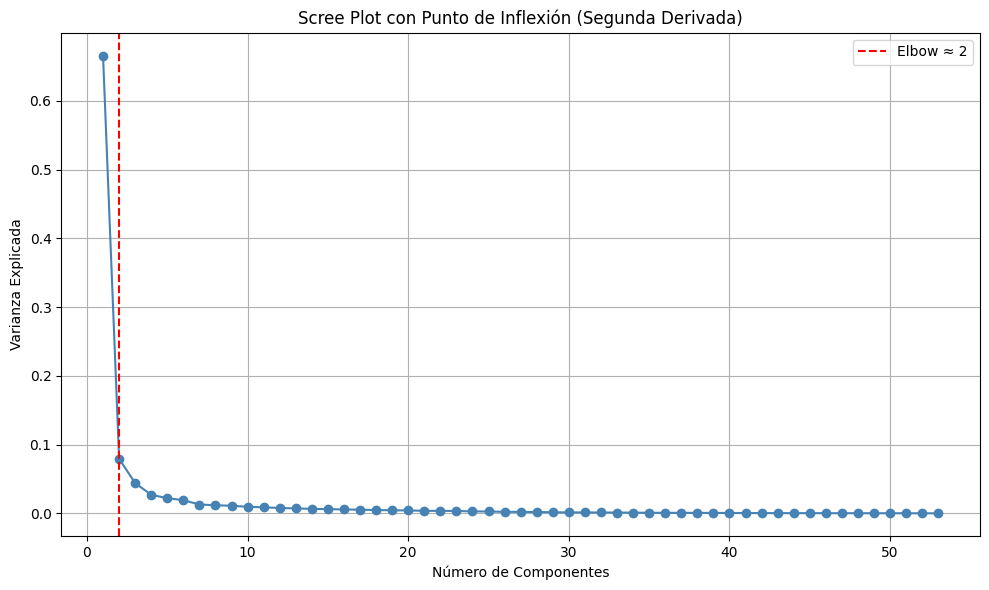

Punto de inflexión sugerido por segunda derivada: 2


In [59]:
# PCA completo
pca_full = PCA()
pca_full.fit(pca_input)

# Varianza explicada
explained_var = pca_full.explained_variance_ratio_

# Segunda derivada
second_derivative = np.diff(explained_var, n=2)
elbow_point = np.argmax(second_derivative) + 2  # +2 para alinear con el número de componentes

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o', linestyle='-', color='steelblue')
plt.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada')
plt.title('Scree Plot con Punto de Inflexión (Segunda Derivada)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Imprimir punto de inflexión
print(f"Punto de inflexión sugerido por segunda derivada: {elbow_point}")

In [60]:
pca_2 = PCA(n_components=2)

In [61]:
countries_win6_pca = pca_2.fit_transform(pca_input)

In [62]:
pca_df = pd.DataFrame(countries_win6_pca, columns=['PC1', 'PC2'])

In [63]:
pca_df.head()

,PC1,PC2
0,1.561776,1.670706
1,-8.143786,1.060732
2,-7.059206,0.497262
3,8.967127,-1.064699
4,-11.177959,-1.908457


In [64]:
print(pca_2.explained_variance_ratio_)
print(pca_2.explained_variance_ratio_.sum())

[0.66549693 0.07931218]
0.7448091106237705


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [65]:
from sklearn.cluster import KMeans

In [66]:
pca_df.head()

,PC1,PC2
0,1.561776,1.670706
1,-8.143786,1.060732
2,-7.059206,0.497262
3,8.967127,-1.064699
4,-11.177959,-1.908457


In [67]:
pca_df.shape

(53, 2)

In [ ]:
from sklearn.metrics import silhouette_samples
from matplotlib import cm

In [22]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [8]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_index_winsorized.parquet')

In [2]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_3_deleted_countries_winsorized4.parquet')

In [9]:
df_hpi_winsorized.shape

(15, 53)

In [11]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [15]:
find_countries_missing_from_clusters(df_hpi_winsorized, one_point_countries_win6)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


['Year']

### Leverage The Law of Large Numbers and compute metrics
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [17]:
import country_converter as coco

In [19]:
one_point_countries_win6['UNregion'] = coco.convert(names=one_point_countries_win6['Country'], to='UNregion')

In [21]:
one_point_countries_win6.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477,Australia and New Zealand
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887,Western Europe
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149,Western Europe
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149,South America
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401,Eastern Europe


In [22]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='Continent', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to plot
    - yearly_bootstrap_means: Dict with year as key and synthetic mean value
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    # Obtener países del cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    # Graficar HPI real por país
    plt.figure(figsize=(12, 6))
    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    # Graficar curva sintética del bootstrap
    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    # Graficar media real del cluster (línea discontinua)
    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    # Estética del gráfico
    plt.title(f"HPI por País en Continente {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [23]:
def calculate_hpi_variance_by_cluster(df_hpi, df_clusters,
                                      cluster_column='Continent', country_column='Country',
                                      year_column='Year'):
    """
    Calculates average HPI variance across countries for each cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values

    Returns:
    - cluster_variances: dict with cluster_id as key and average variance as value
    """
    cluster_variances = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Get countries in this cluster that are present in HPI data
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_variances[cluster_id] = np.nan
            continue

        # Extract HPI values for cluster countries
        hpi_values = df_hpi[cluster_countries]

        # Calculate variance across countries for each year
        yearly_variances = hpi_values.var(axis=1, skipna=True)

        # Compute average variance across all years
        avg_variance = yearly_variances.mean()
        cluster_variances[cluster_id] = avg_variance

    return cluster_variances

In [24]:
def evaluate_cluster_sampling_errors(df_hpi, df_clusters, cluster_id,
                                     cluster_column='Continent', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None, start_year=None):

    """
    Evaluates synthetic HPI estimation via bootstrap sampling for each country in a cluster.

    Returns:
    - avg_mse: Average MSE across all countries in the cluster
    - avg_mae: Average MAE across all countries in the cluster
    - best_country: Country with the lowest MSE
    - yearly_bootstrap_means: Dict with year as key and synthetic mean using best_country as excluded
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    if start_year is not None:
        df_hpi = df_hpi[df_hpi[year_column] >= start_year]

    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data.")

    mse_scores = {}
    mae_scores = {}

    for excluded_country in cluster_countries:
        sampling_countries = [c for c in cluster_countries if c != excluded_country]
        synthetic_values = []
        actual_values = []

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(excluded_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            synthetic_mean = np.mean(sample_means)

            synthetic_values.append(synthetic_mean)
            actual_values.append(actual_value)

        if len(synthetic_values) == 0:
            mse_scores[excluded_country] = np.nan
            mae_scores[excluded_country] = np.nan
        else:
            errors = np.array(synthetic_values) - np.array(actual_values)
            mse_scores[excluded_country] = np.mean(errors ** 2)
            mae_scores[excluded_country] = np.mean(np.abs(errors))

    best_country = min(mse_scores, key=lambda k: mse_scores[k] if not np.isnan(mse_scores[k]) else np.inf)

    # Plot for best country
    if plot:
        synthetic_values = []
        actual_values = []
        years = []

        sampling_countries = [c for c in cluster_countries if c != best_country]

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(best_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            cumulative_means = [np.mean(sample_means[:j+1]) for j in range(n_samples)]

            lower_bound = np.percentile(sample_means, 2.5)
            upper_bound = np.percentile(sample_means, 97.5)

            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {best_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(cumulative_means, color='purple')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

    # Synthetic mean per year using best_country as excluded
    yearly_bootstrap_means = {}
    sampling_countries = [c for c in cluster_countries if c != best_country]

    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[sampling_countries].dropna().values

        if len(values) == 0:
            continue

        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]
        synthetic_mean = np.mean(sample_means)
        yearly_bootstrap_means[year] = synthetic_mean

    # Real mean per year using all countries in the cluster
    yearly_mean = {}
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[cluster_countries].dropna().values

        if len(values) == 0:
            continue

        yearly_mean[year] = np.mean(values)

    avg_mse = np.nanmean(list(mse_scores.values()))
    avg_mae = np.nanmean(list(mae_scores.values()))

    return avg_mse, avg_mae, best_country, yearly_bootstrap_means, yearly_mean

In [25]:
def count_points_within_iqr_by_cluster(df_hpi, df_clusters,
                                       cluster_column='Continent', country_column='Country',
                                       year_column='Year'):
    """
    Cuenta cuántos puntos de HPI están dentro del IQR (Q1–Q3) por cluster.

    Returns:
    - dict con cluster_id como clave y cantidad total de puntos dentro del IQR como valor
    """
    cluster_iqr_counts = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Obtener países del cluster presentes en df_hpi
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_iqr_counts[cluster_id] = 0
            continue

        # Extraer valores de HPI para esos países
        hpi_values = df_hpi[cluster_countries]

        total_within_iqr = 0

        # Iterar por año
        for _, row in hpi_values.iterrows():
            values = row.dropna().values
            if len(values) < 2:
                continue

            q1 = np.percentile(values, 25)
            q3 = np.percentile(values, 75)

            # Contar cuántos valores están dentro del IQR
            count = np.sum((values >= q1) & (values <= q3))
            total_within_iqr += count

        cluster_iqr_counts[cluster_id] = total_within_iqr

    return cluster_iqr_counts

In [79]:
def plot_region_clusters(df, x_col, y_col, region_col='UNregion',
                         country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    regions = df[region_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por región
    unique_regions = sorted(df[region_col].unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    region_color_map = {region: colors[i % len(colors)] for i, region in enumerate(unique_regions)}
    region_marker_map = {region: markers[i % len(markers)] for i, region in enumerate(unique_regions)}

    # Graficar cada región
    for region in unique_regions:
        region_mask = (regions == region)
        region_color = region_color_map[region]
        region_marker = region_marker_map[region]

        # Separar Paraguay del resto
        paraguay_mask = region_mask & (countries == highlight_country)
        others_mask = region_mask & (countries != highlight_country)

        # Graficar otros países de la región
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=region_color, marker=region_marker,
                    edgecolor='black', label=f'{region}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=region_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} ({region})')

    plt.xlabel(x_col)
    plt.ylabel(y_col)

    # 🧭 Mover la leyenda al costado derecho
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Regional Clustering: {x_col} vs {y_col}')
    plt.show()

In [28]:
one_point_countries_win6.UNregion.unique()

array(['Australia and New Zealand', 'Western Europe', 'South America',
       'Eastern Europe', 'Northern America', 'Southern Europe',
       'Western Asia', 'Northern Europe', 'Southern Asia', 'Eastern Asia',
       'South-eastern Asia', 'Central America', 'Southern Africa'],
      dtype=object)

In [31]:
one_point_countries_win6[one_point_countries_win6["UNregion"]=="Australia and New Zealand"]

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477,Australia and New Zealand
31,New Zealand,1.351703,1.353255,0.136062,1.311032,1.403643,1.403643,4.610456,4.611649,1.027869,...,0.965464,0.138675,0.785894,0.907102,0.913343,-0.235302,-0.330129,0.171363,-0.915149,Australia and New Zealand


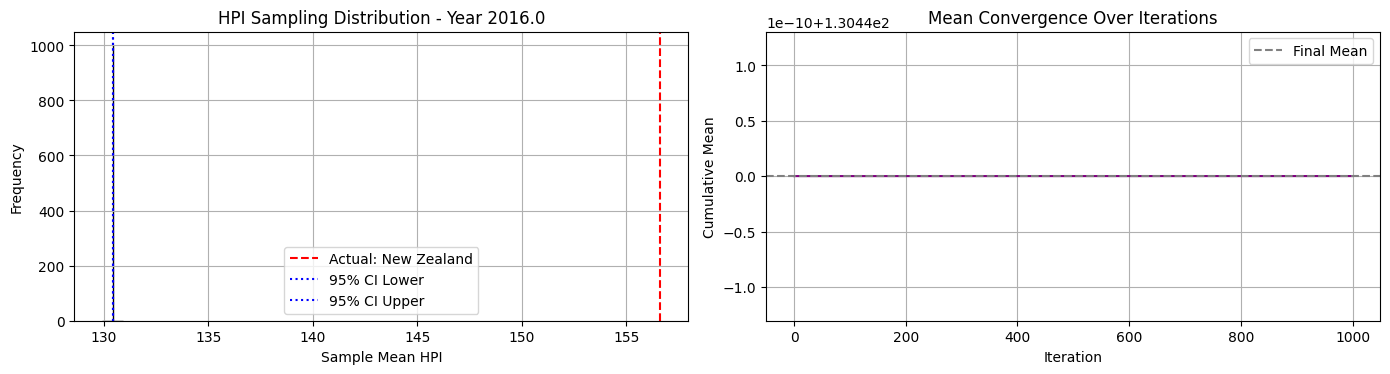

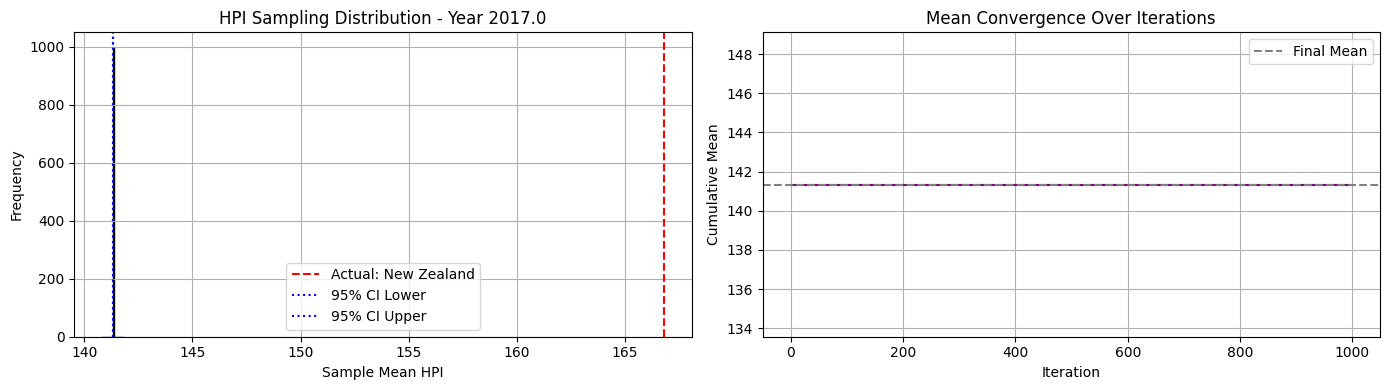

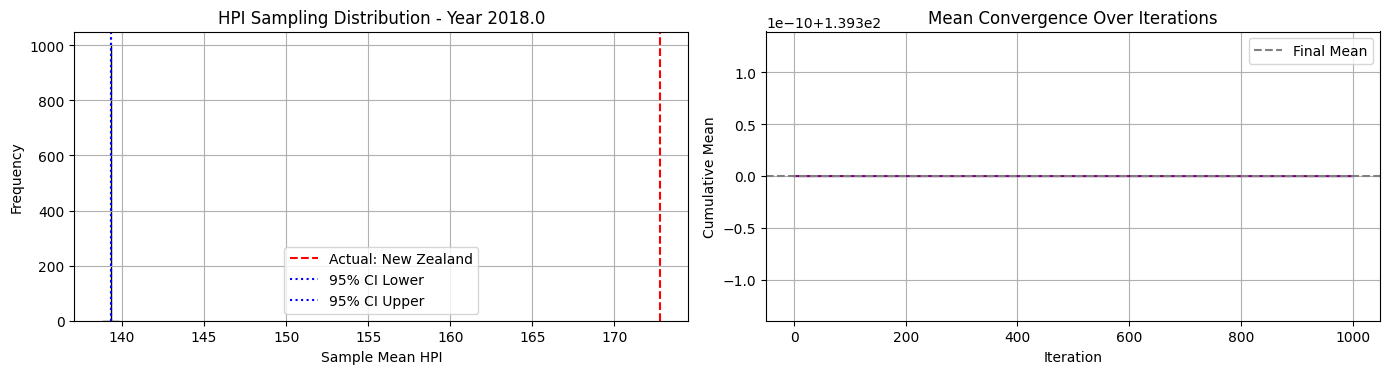

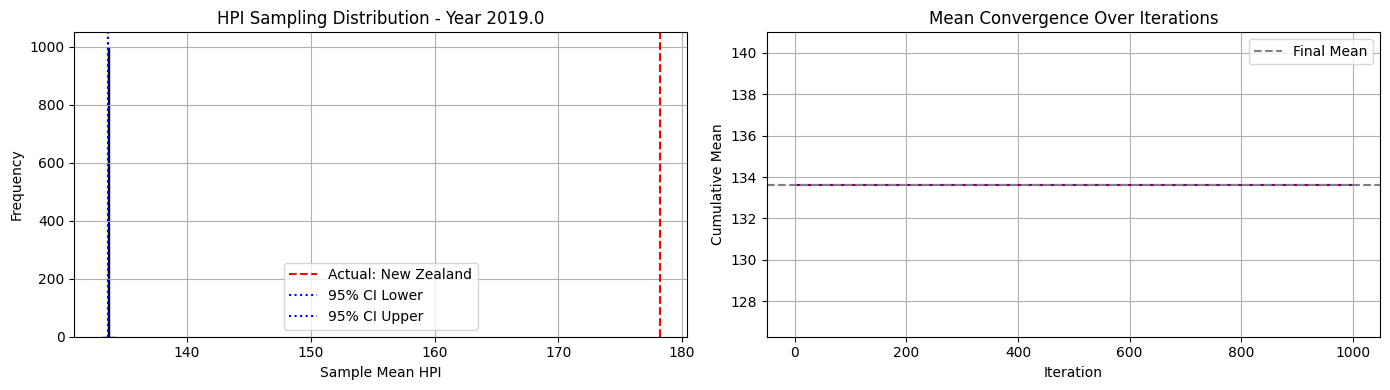

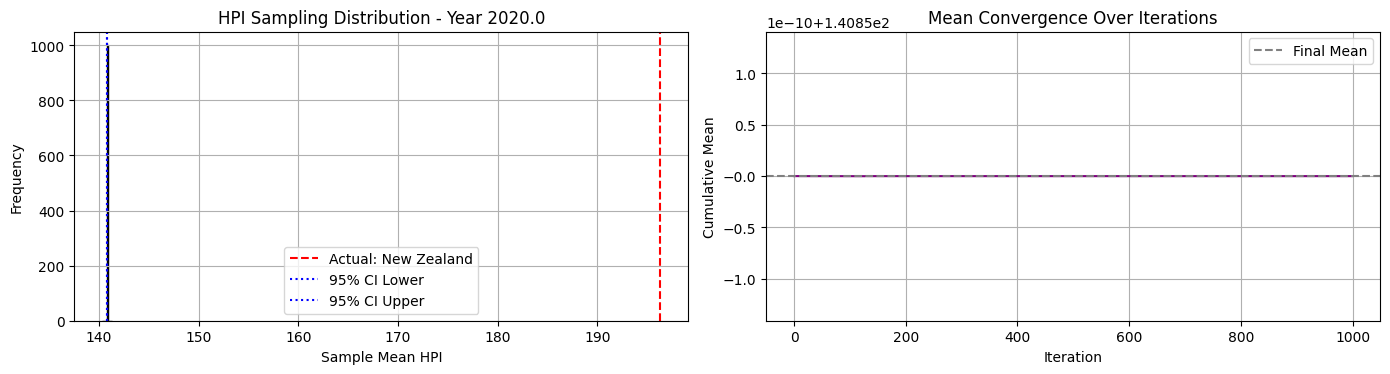

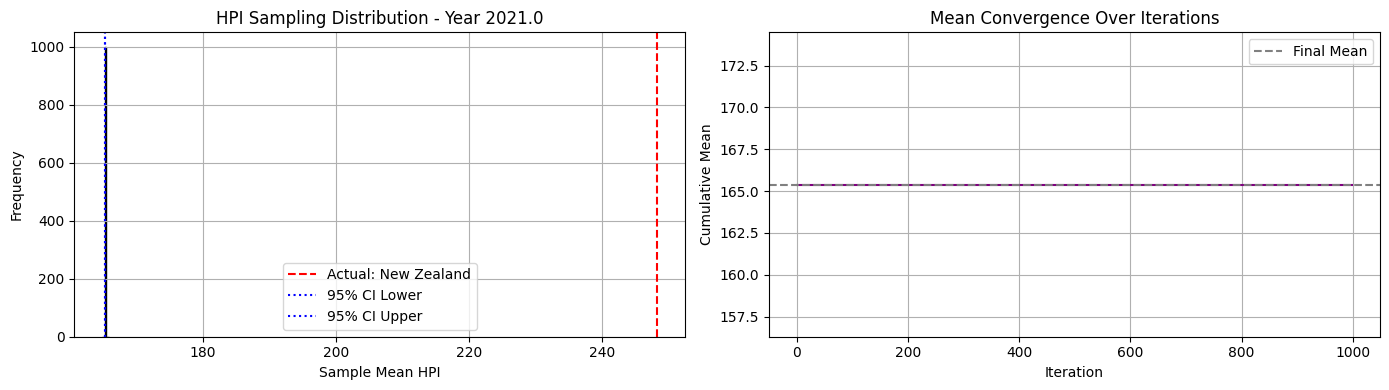

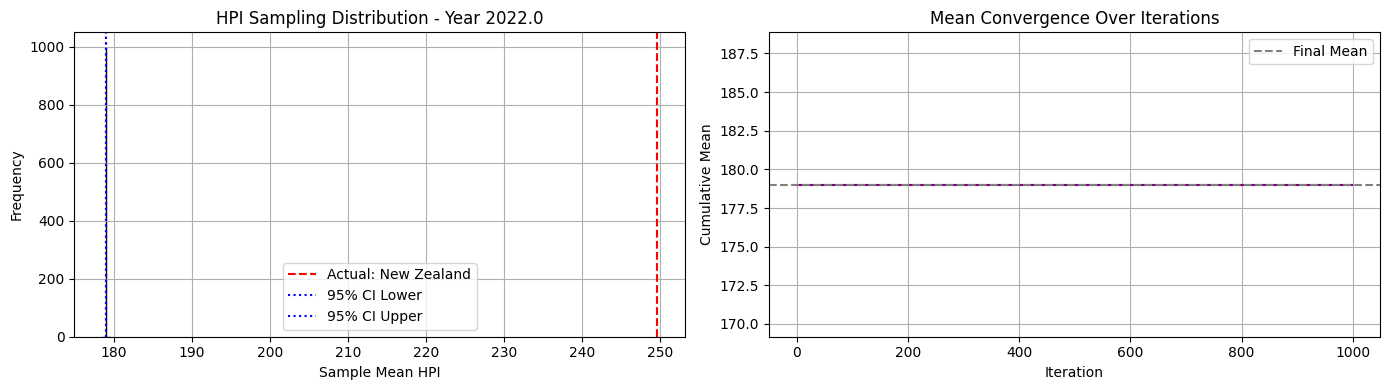

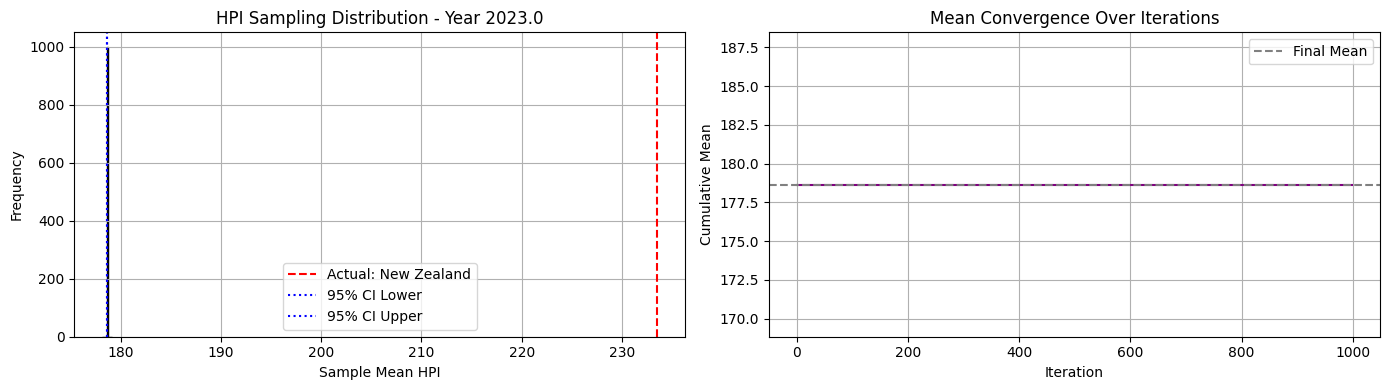

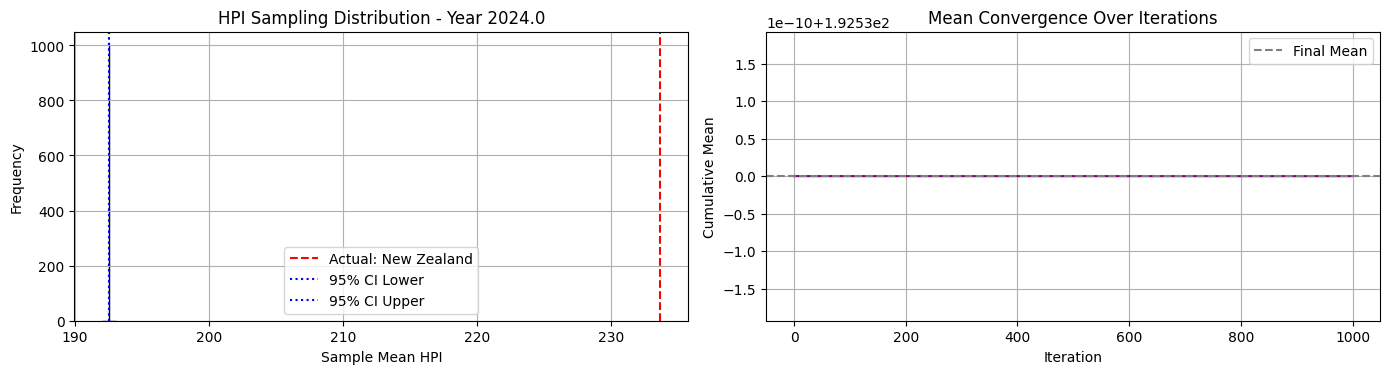

In [33]:
avg_mse_00, avg_mae_00, best_country_00, yearly_bootstrap_means_00, yearly_mean_00 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="Australia and New Zealand", cluster_column="UNregion", start_year=2016)

In [34]:
one_point_countries_win6[one_point_countries_win6["UNregion"]=="Western Europe"]

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887,Western Europe
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149,Western Europe
14,France,3.467484,3.456159,0.470640,3.447763,3.495901,3.495901,4.582413,4.585987,1.318929,...,0.533971,0.138675,0.560889,0.548940,0.402967,-0.240457,0.261000,-0.714821,-0.733260,Western Europe
15,Germany,3.719821,3.718924,0.298534,3.706474,3.736955,3.733375,4.582413,4.588024,1.289023,...,0.718897,0.138675,0.627067,0.879551,0.468400,-0.268474,0.345947,-0.714821,-0.915149,Western Europe
26,Luxembourg,1.351703,1.342865,0.061296,1.311032,1.388791,1.388791,4.709440,4.731362,2.047482,...,0.965464,0.138675,0.852072,0.907102,0.991862,-0.151530,0.825197,0.333373,0.840380,Western Europe
30,Netherlands,2.352803,2.349469,0.282939,2.314514,2.399712,2.399712,4.617099,4.617099,1.061979,...,0.965464,0.138675,0.852072,0.907102,0.991862,-0.221808,-0.822060,-0.221307,-0.557503,Western Europe
48,Switzerland,1.784735,1.786747,0.061296,1.773256,1.793425,1.793425,4.588126,4.585987,1.027869,...,0.965464,0.138675,0.852072,0.907102,0.991862,-0.172014,0.825197,0.418830,0.840380,Western Europe


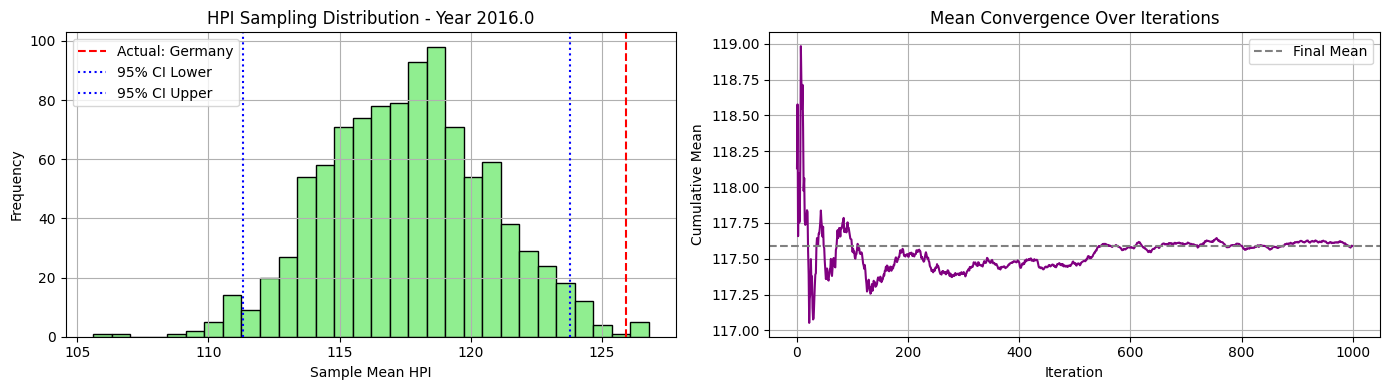

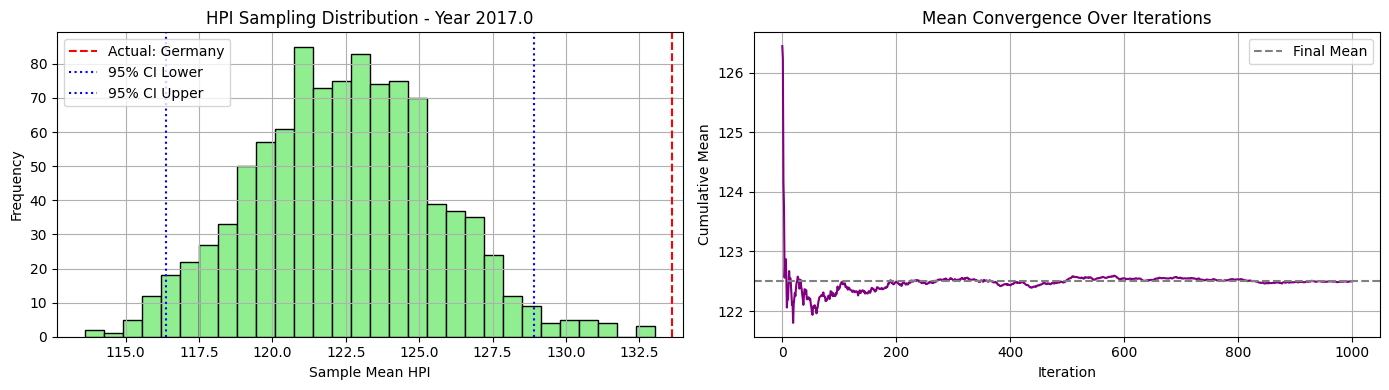

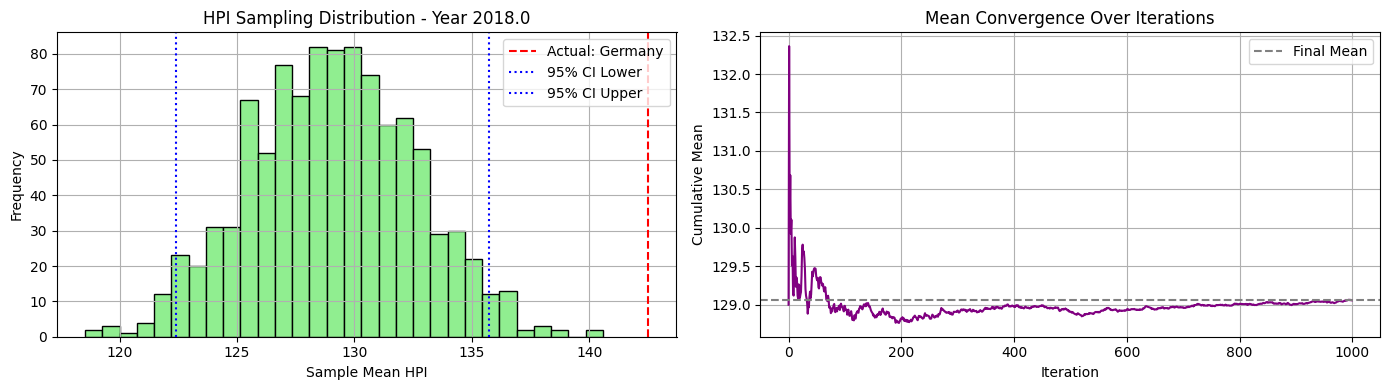

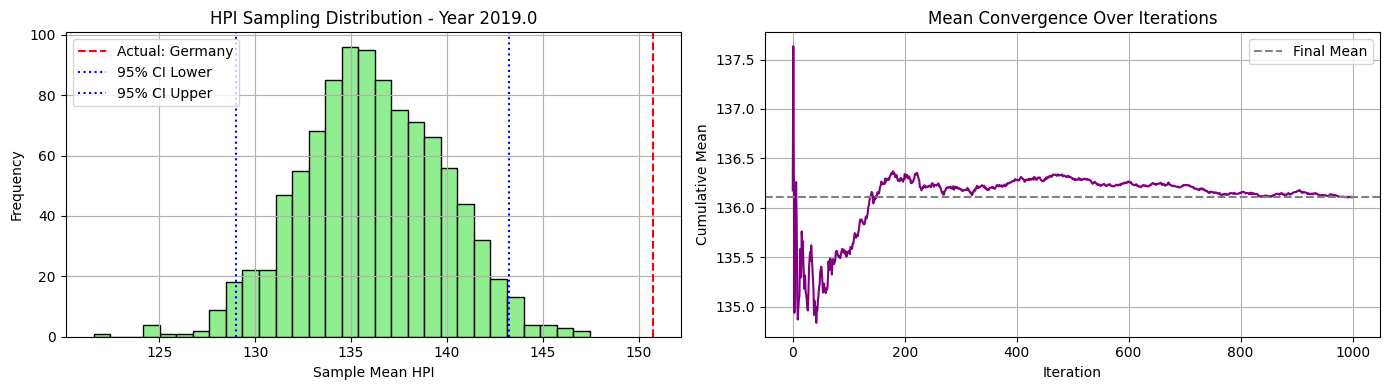

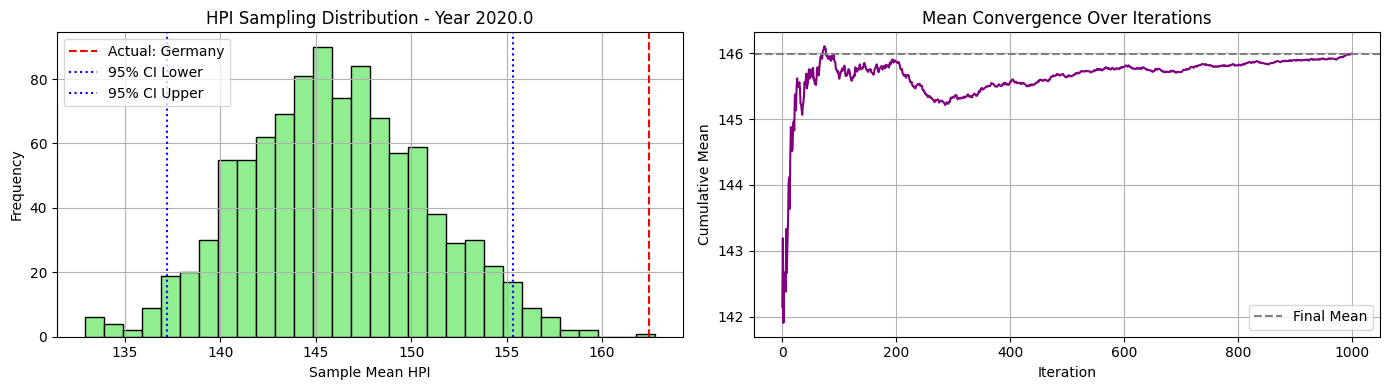

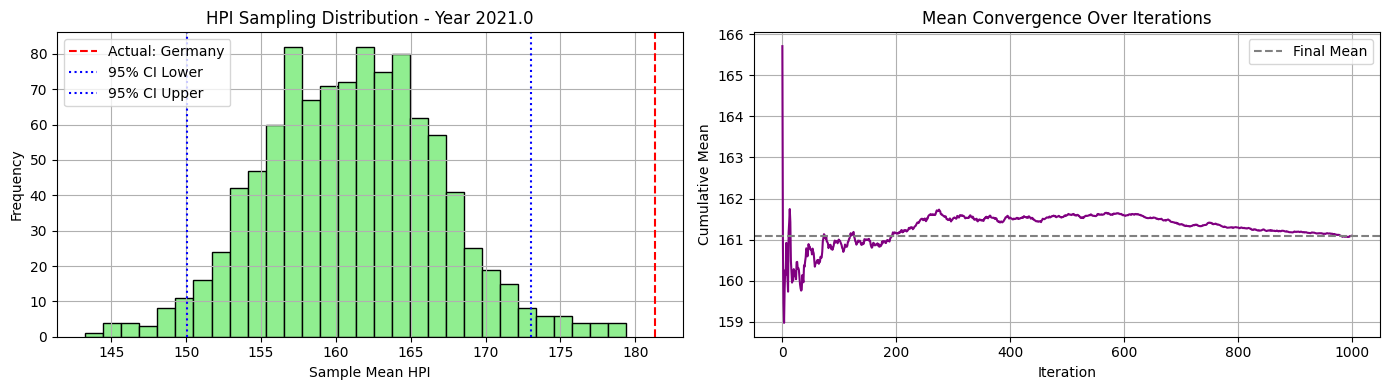

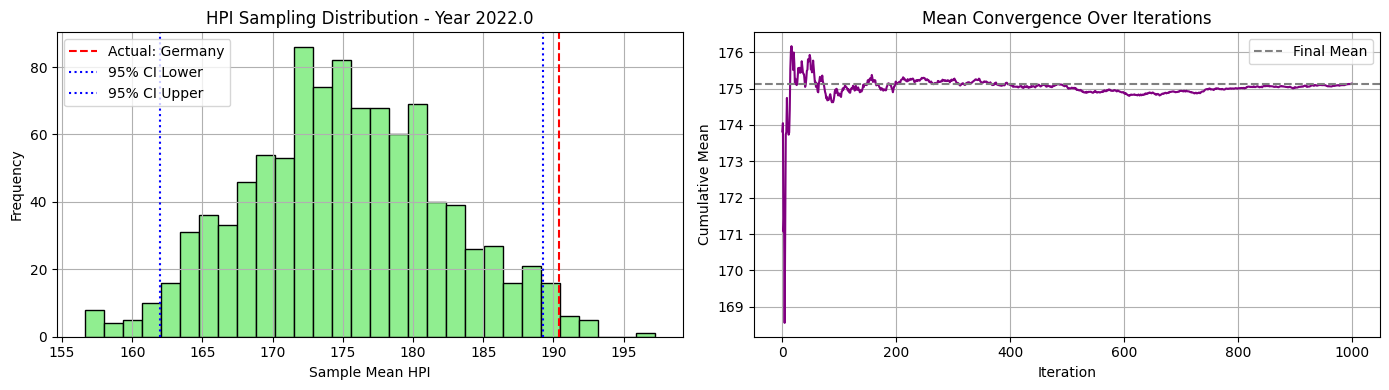

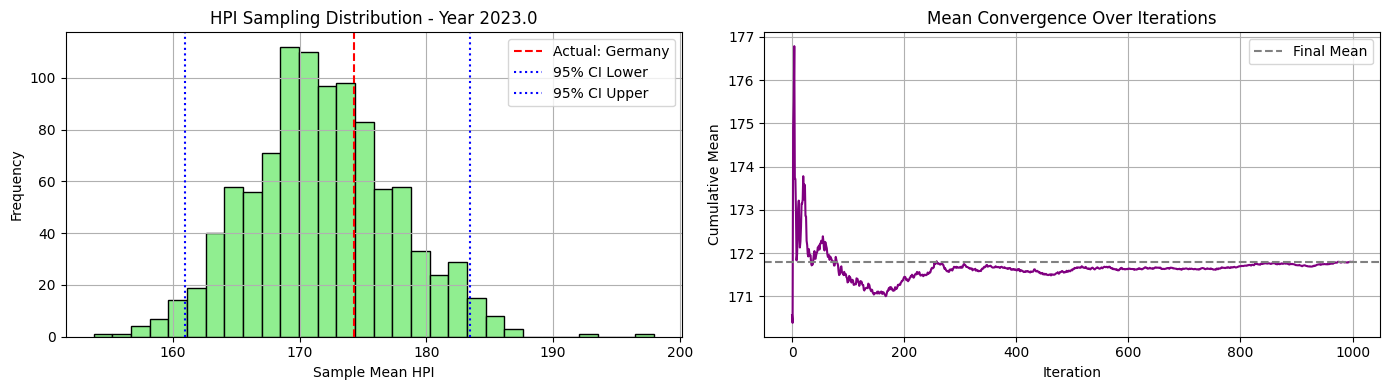

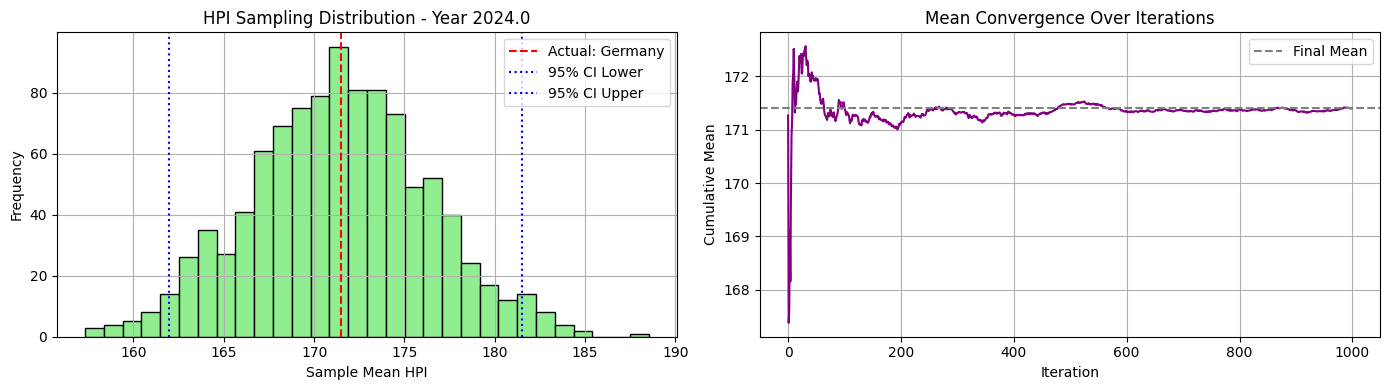

In [36]:
avg_mse_01, avg_mae_01, best_country_01, yearly_bootstrap_means_01, yearly_mean_01 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="Western Europe", cluster_column="UNregion", start_year=2016)

In [55]:
df_continet[df_continet["UNregion"]=="South America"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
3,9.370254,-1.189187,1,Brazil,BRA,America,South America
6,11.313440,-3.520124,1,Chile,CHL,America,South America
7,12.057846,-5.641059,1,Colombia,COL,America,South America
32,10.529278,-8.589597,1,Paraguay,PRY,America,South America
33,-3.223028,-1.718274,0,Peru,PER,America,South America


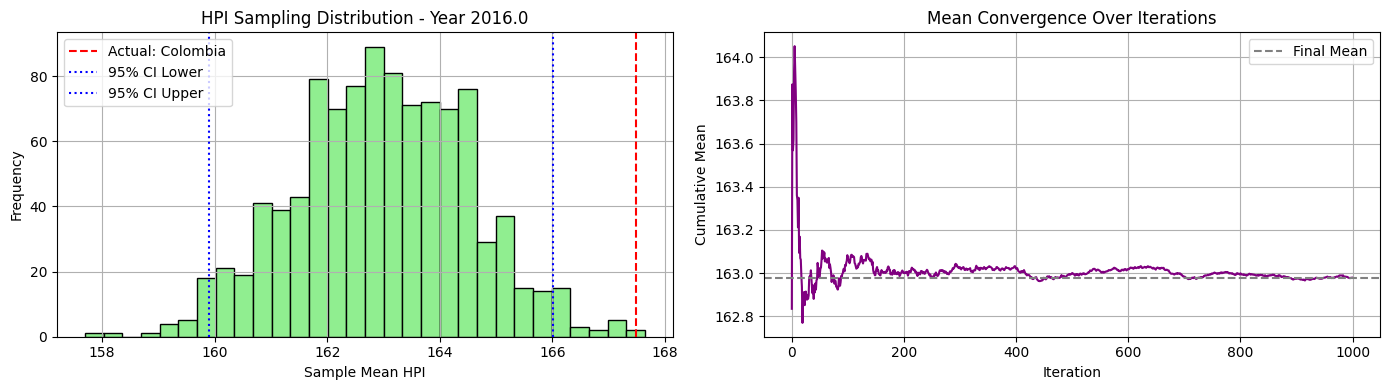

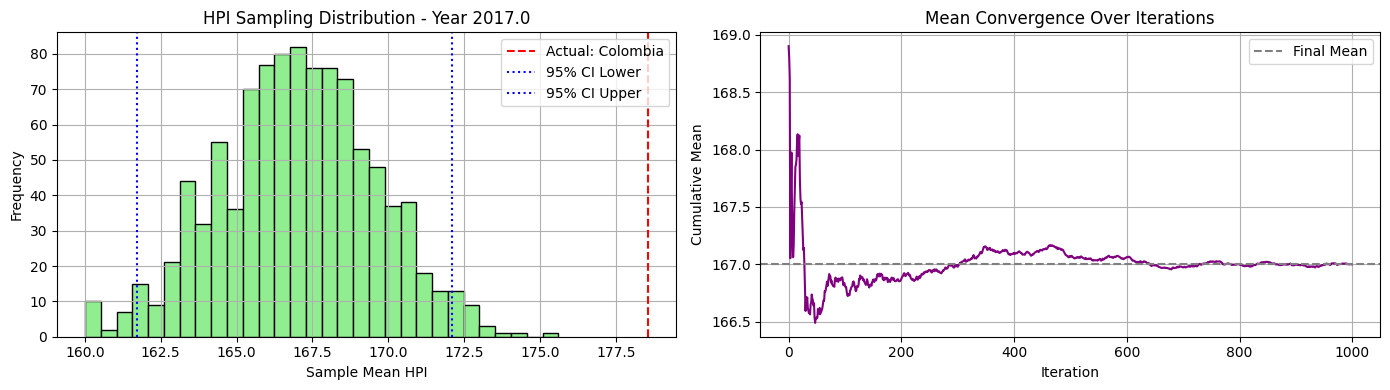

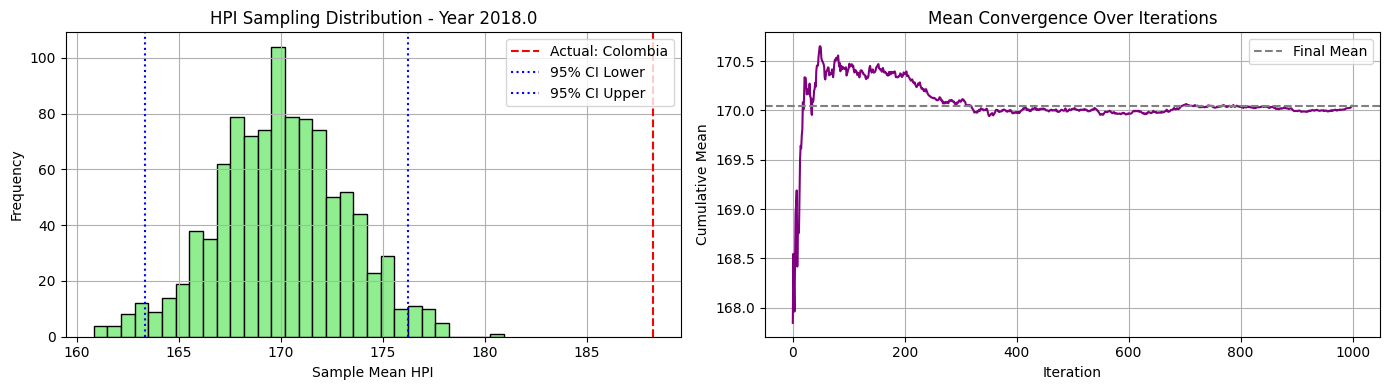

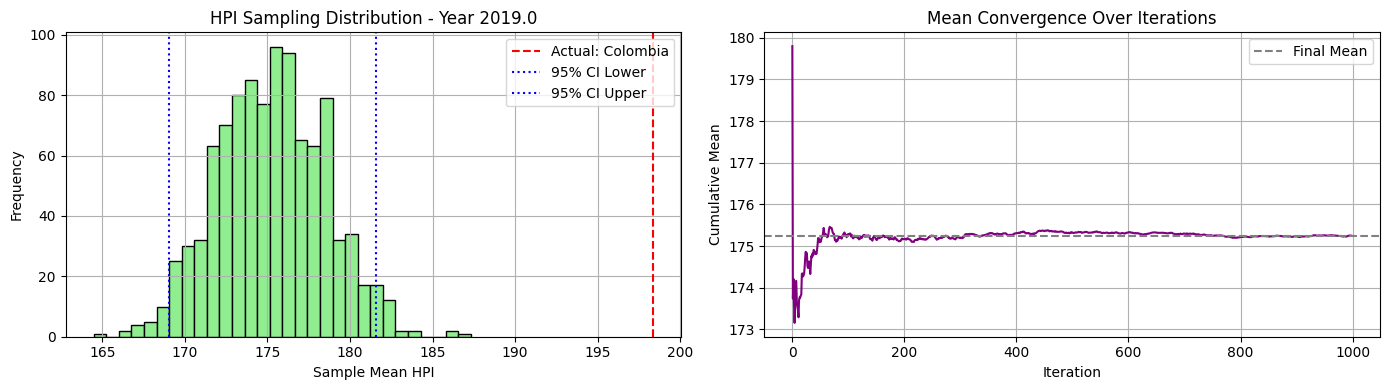

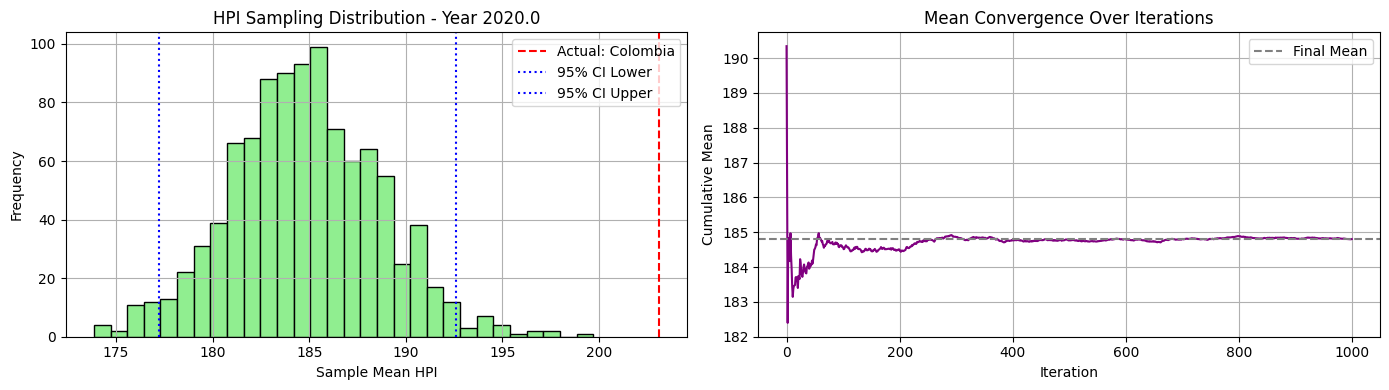

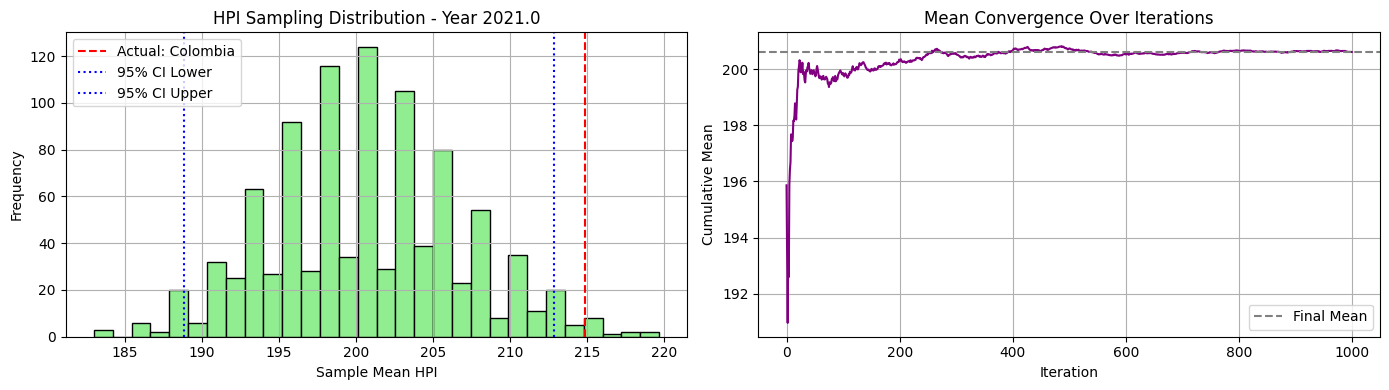

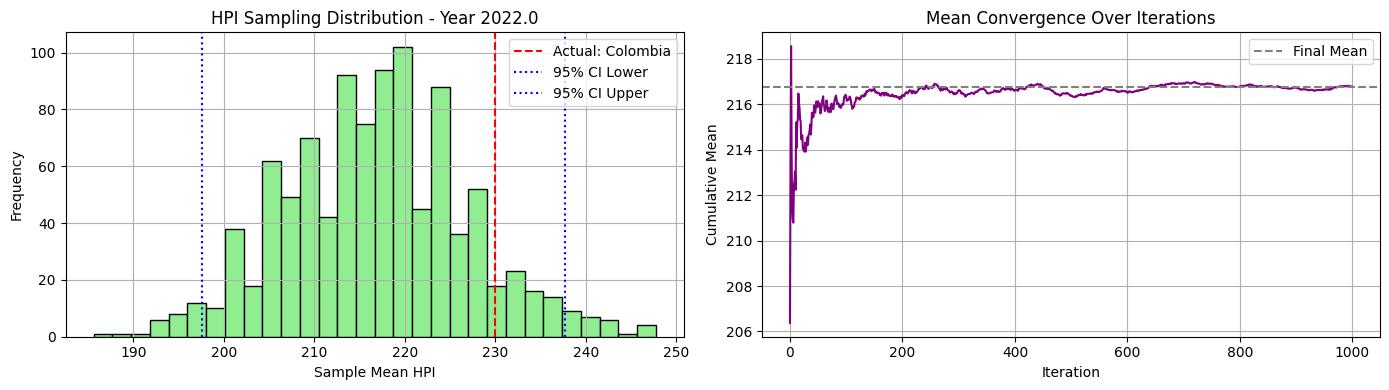

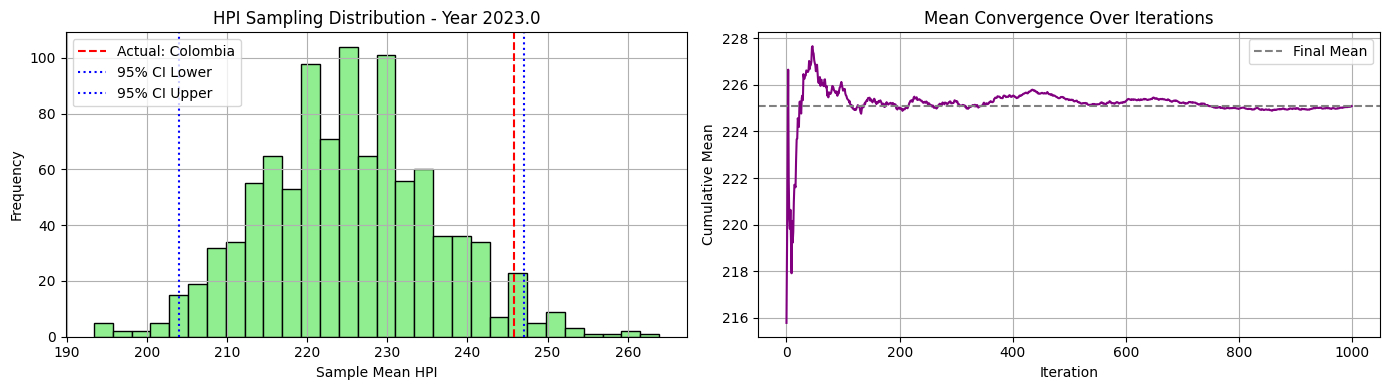

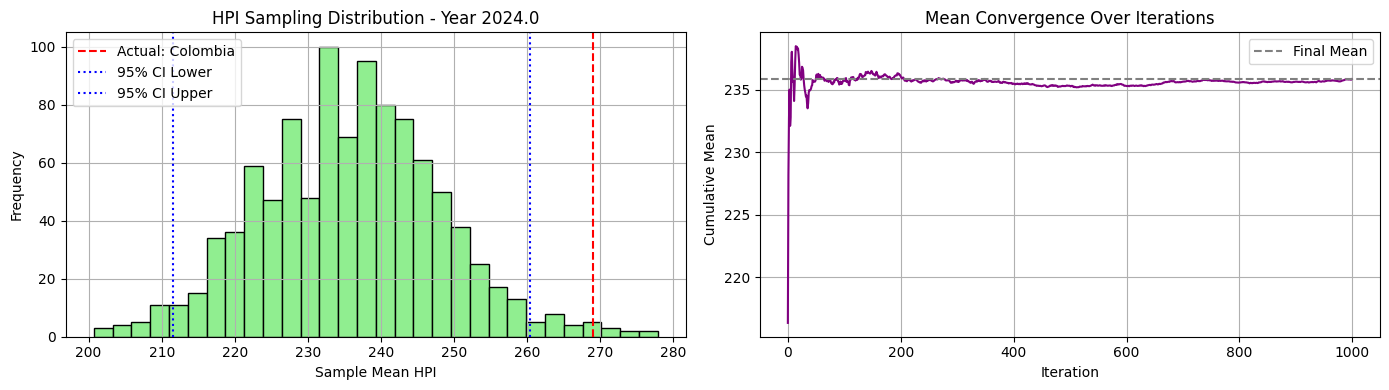

In [37]:
avg_mse_02, avg_mae_02, best_country_02, yearly_bootstrap_means_02, yearly_mean_02 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="South America", cluster_column="UNregion", start_year=2016)

In [86]:
df_continet[df_continet["UNregion"]=="Eastern Europe"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
4,-10.818940,-1.642285,0,Bulgaria,BGR,Europe,Eastern Europe
10,7.656329,1.924567,1,Czech Republic,CZE,Europe,Eastern Europe
17,10.849171,-5.055863,1,Hungary,HUN,Europe,Eastern Europe
35,3.194950,1.379322,1,Poland,POL,Europe,Eastern Europe
37,-1.920823,-2.860329,0,Romania,ROU,Europe,Eastern Europe
38,13.775198,-0.769284,1,Russia,RUS,Europe,Eastern Europe
41,-12.098298,-2.664210,0,Slovakia,SVK,Europe,Eastern Europe


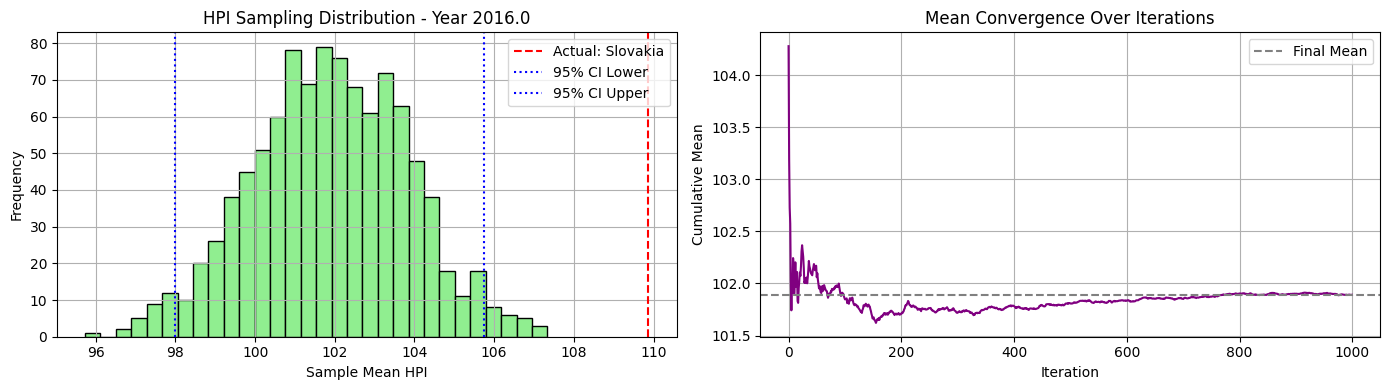

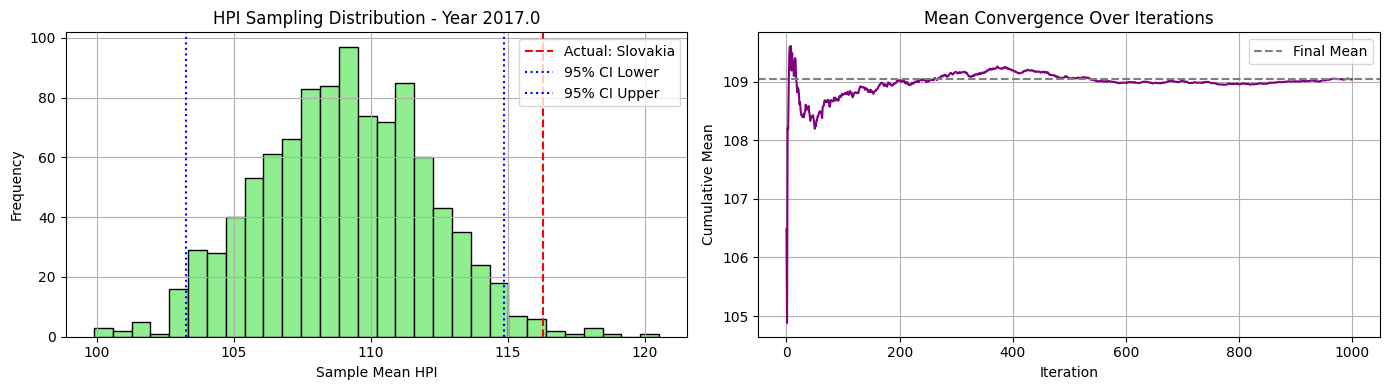

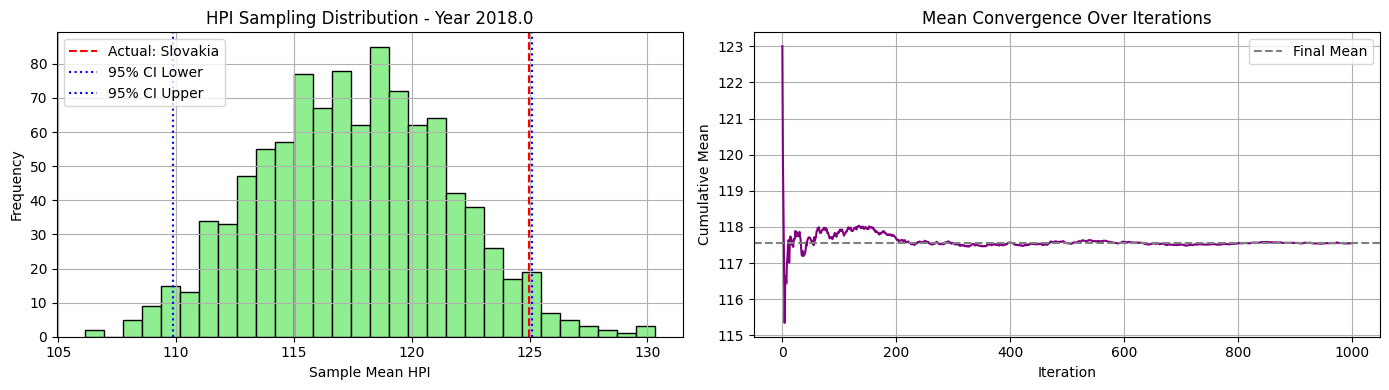

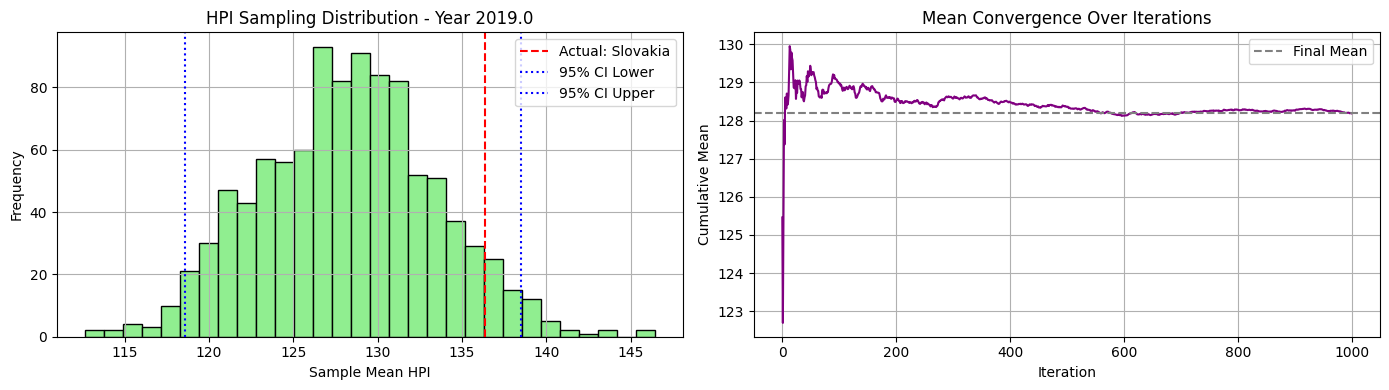

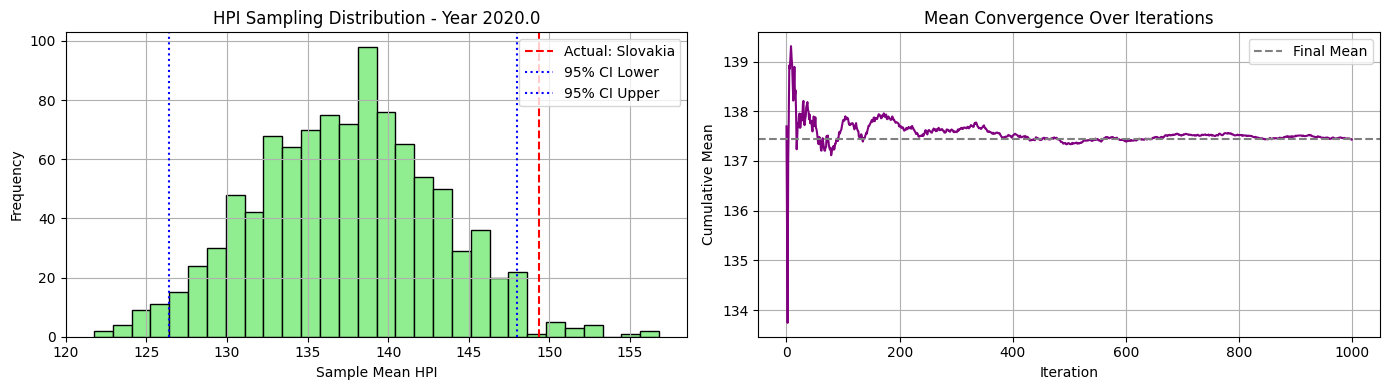

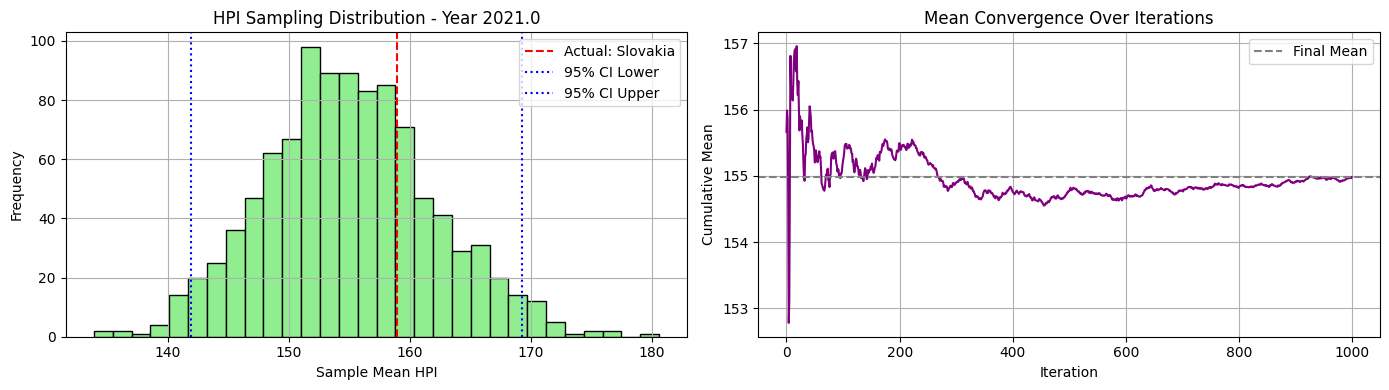

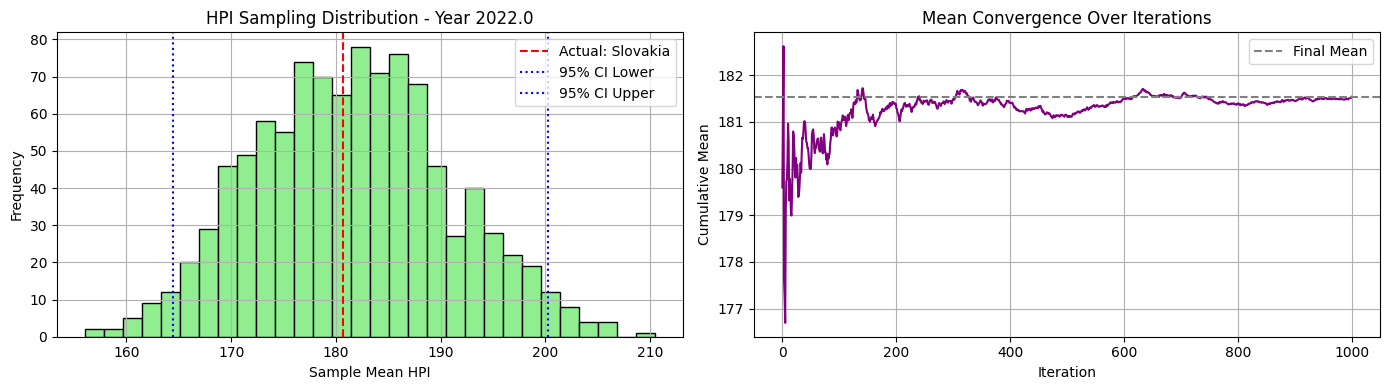

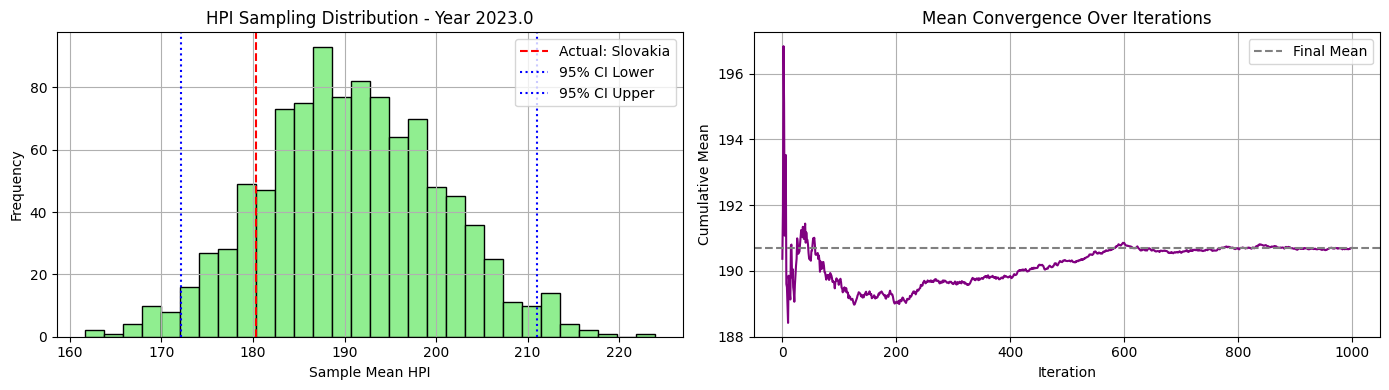

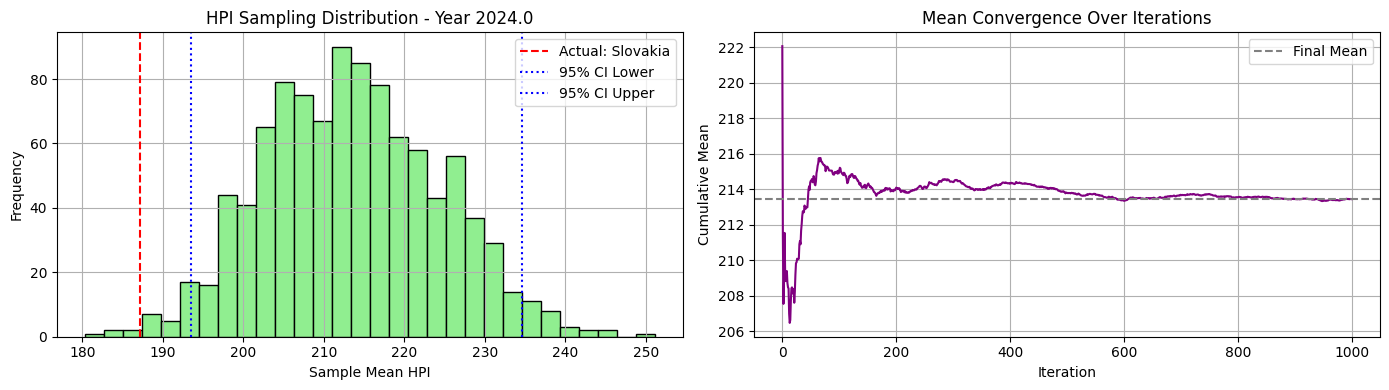

In [38]:
avg_mse_03, avg_mae_03, best_country_03, yearly_bootstrap_means_03, yearly_mean_03 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="Eastern Europe", cluster_column="UNregion", start_year=2016)

In [39]:
one_point_countries_win6[one_point_countries_win6["UNregion"]=="Northern America"]

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion
5,Canada,3.082552,3.073850,0.586940,3.038792,3.141563,3.141563,4.709440,4.731362,2.044840,...,0.965464,0.138675,0.852072,0.907102,0.900256,-0.227721,0.686410,-0.417763,-0.729173,Northern America
52,USA,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.676653,4.691806,1.581765,...,0.670953,0.138675,0.666774,0.714245,0.507660,-0.234787,0.420733,-0.714821,-0.829314,Northern America


In [41]:
one_point_countries_win6[one_point_countries_win6["UNregion"]=="Central America"]

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion
29,Mexico,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.70944,4.731362,2.047482,...,-1.12351,0.138675,-1.00091,-1.200545,-1.023467,-0.126735,0.825197,-0.648213,-0.322479,Central America


In [42]:
one_point_countries_win6.loc[one_point_countries_win6["Country"] == "Mexico", "UNregion"] = "Northern America"

In [43]:
one_point_countries_win6[one_point_countries_win6["UNregion"]=="Northern America"]

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion
5,Canada,3.082552,3.073850,0.586940,3.038792,3.141563,3.141563,4.709440,4.731362,2.044840,...,0.965464,0.138675,0.852072,0.907102,0.900256,-0.227721,0.686410,-0.417763,-0.729173,Northern America
29,Mexico,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.709440,4.731362,2.047482,...,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.648213,-0.322479,Northern America
52,USA,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.676653,4.691806,1.581765,...,0.670953,0.138675,0.666774,0.714245,0.507660,-0.234787,0.420733,-0.714821,-0.829314,Northern America


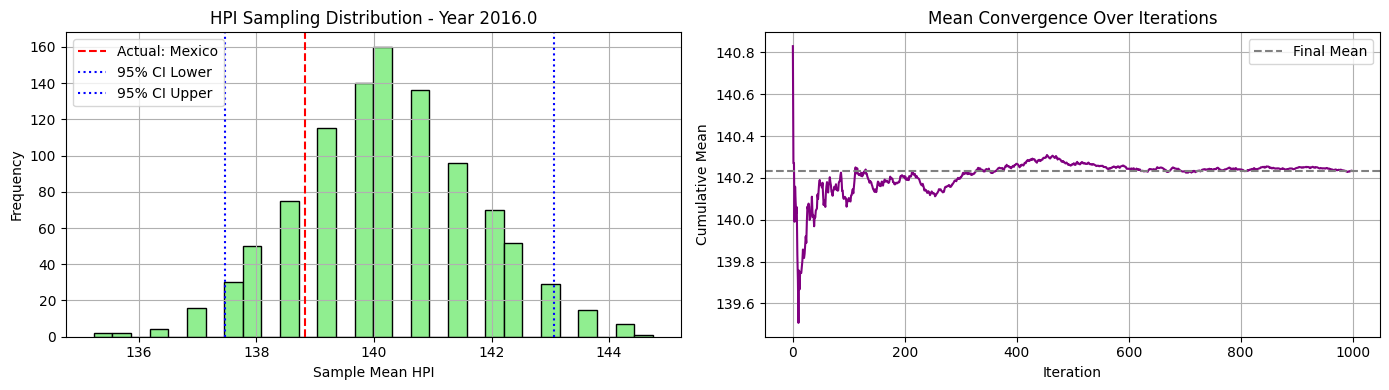

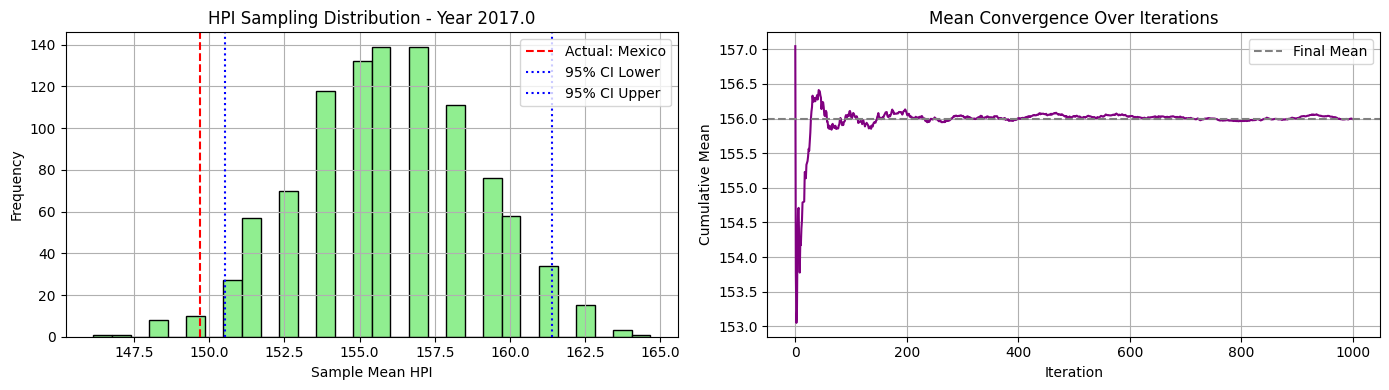

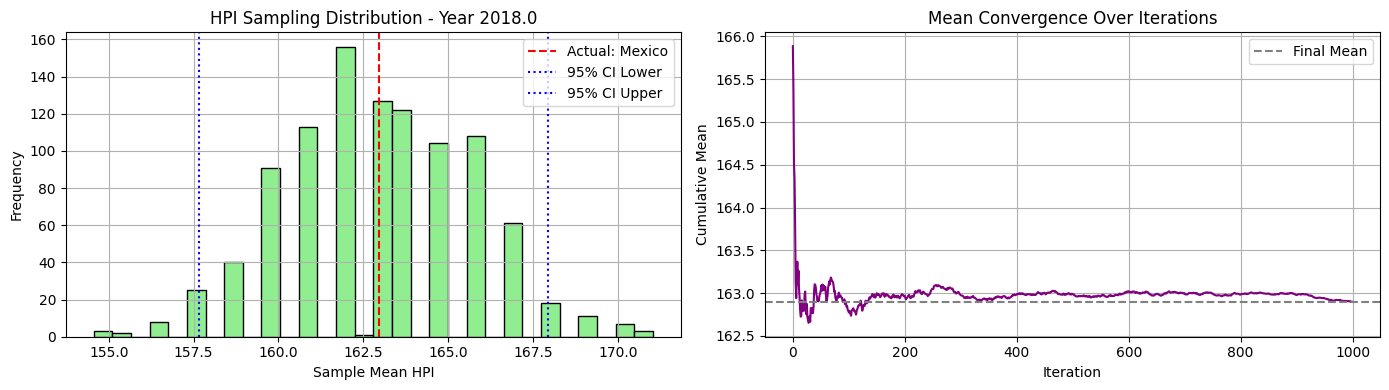

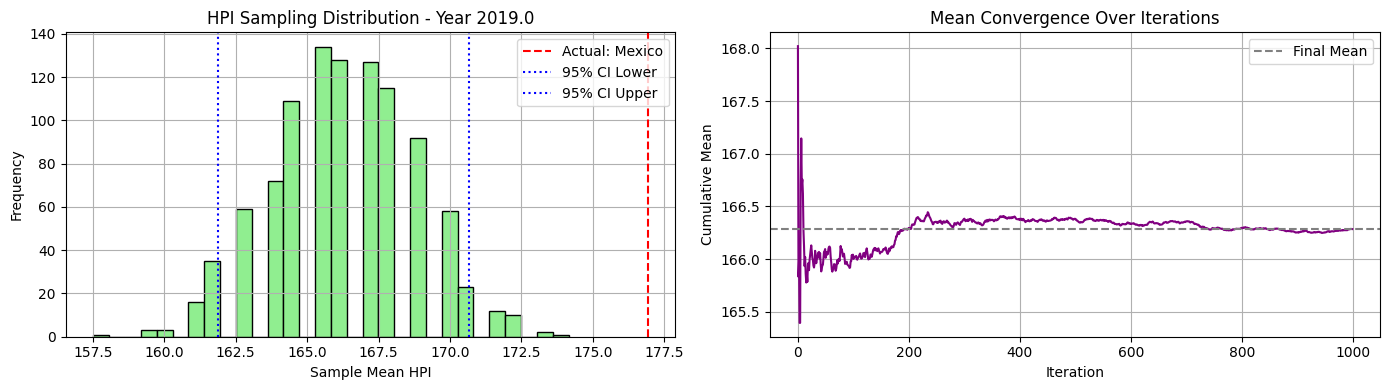

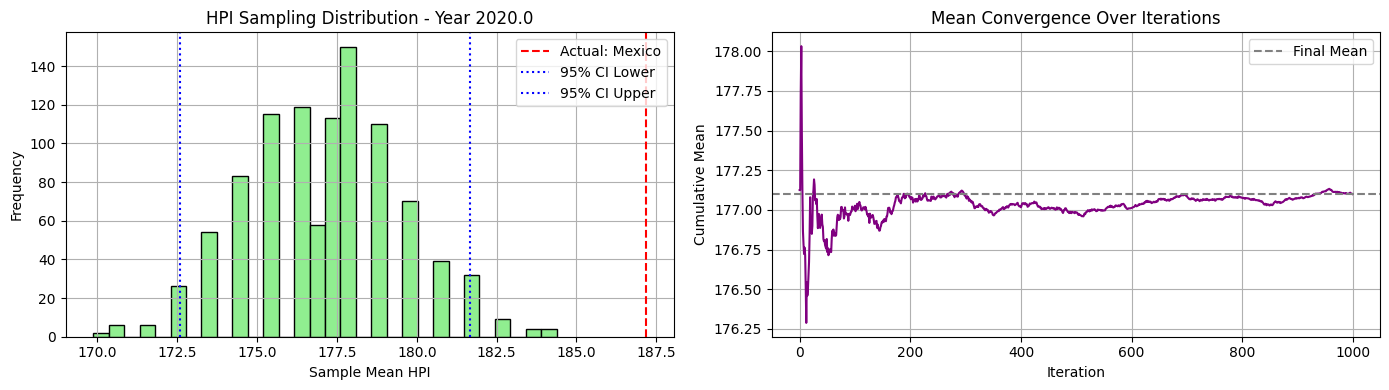

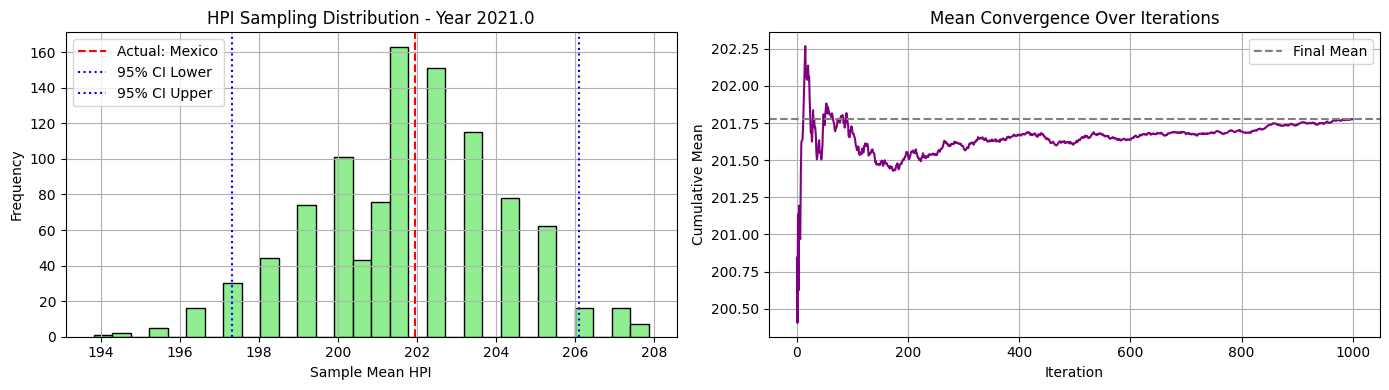

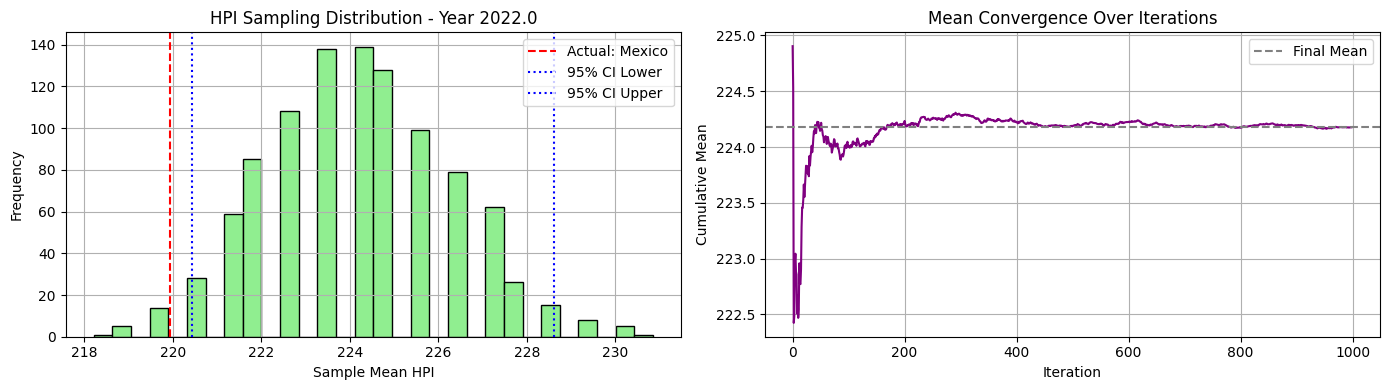

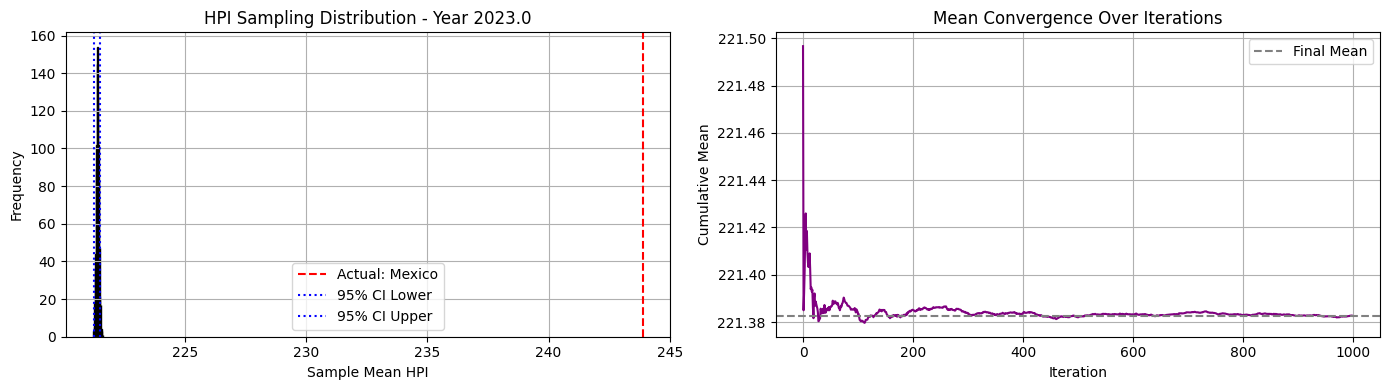

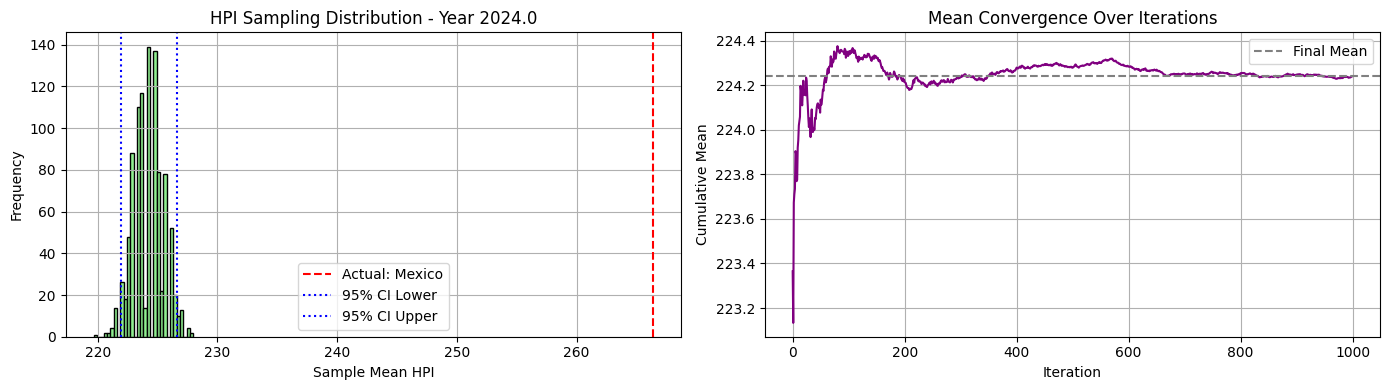

In [44]:
avg_mse_04, avg_mae_04, best_country_04, yearly_bootstrap_means_04, yearly_mean_04 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="Northern America", cluster_column="UNregion", start_year=2016)

In [38]:
df_continet[df_continet["UNregion"]=="Southern Europe"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
8,-12.115571,-2.024072,0,Croatia,HRV,Europe,Southern Europe
16,-11.998487,-3.629059,0,Greece,GRC,Europe,Southern Europe
21,0.463777,0.596509,1,Italy,ITA,Europe,Southern Europe
27,-11.609290,-1.013082,0,Malta,MLT,Europe,Southern Europe
36,-10.684799,-0.239316,0,Portugal,PRT,Europe,Southern Europe
39,5.359881,-6.541855,1,Serbia,SRB,Europe,Southern Europe
42,-12.189767,-1.540384,0,Slovenia,SVN,Europe,Southern Europe
45,-1.284110,0.487111,0,Spain,ESP,Europe,Southern Europe


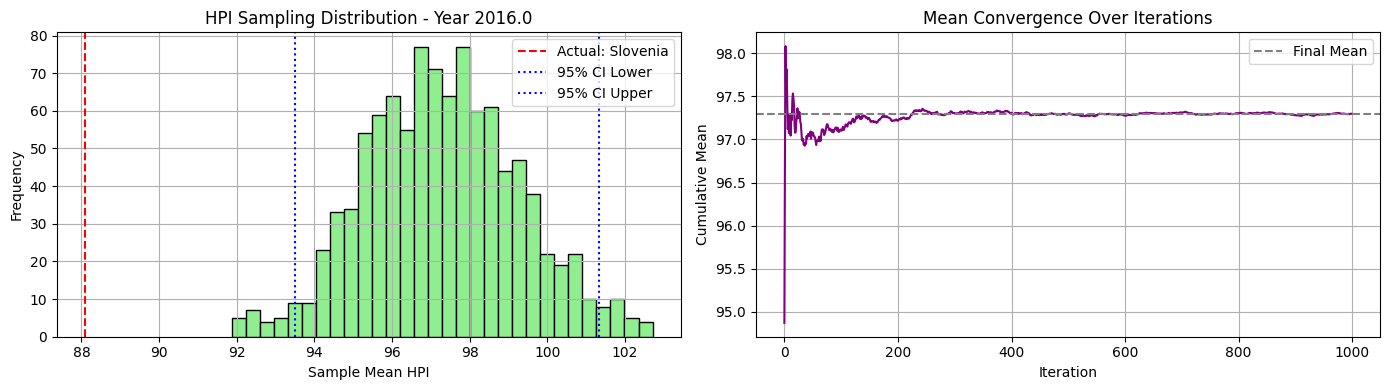

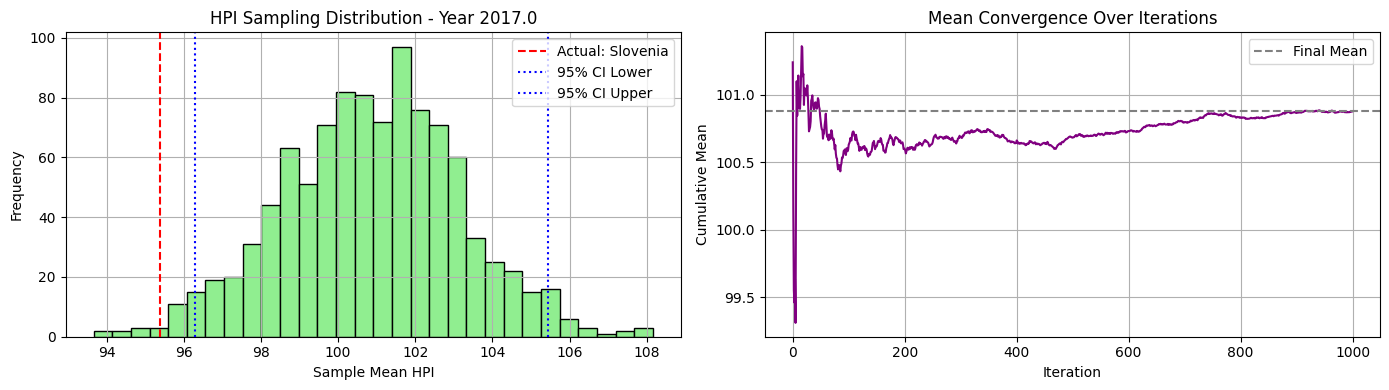

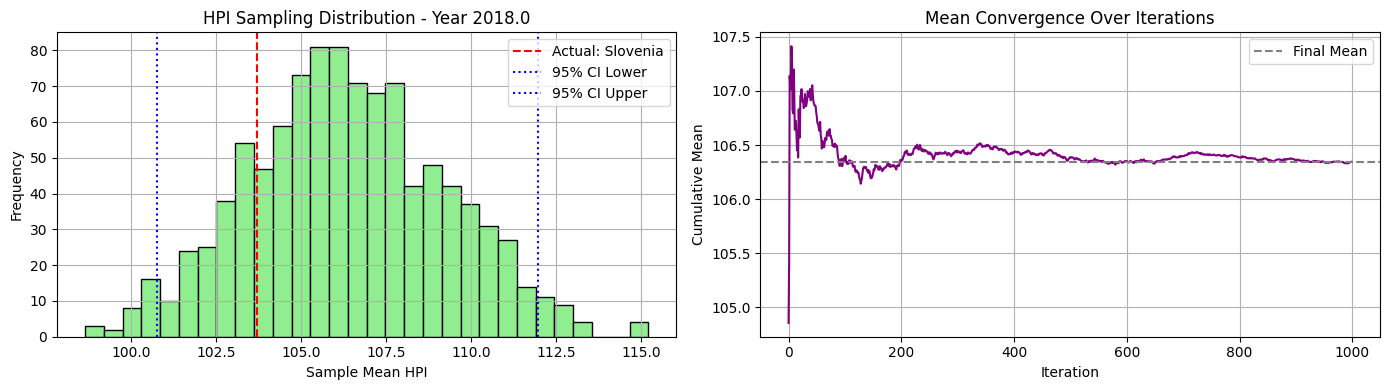

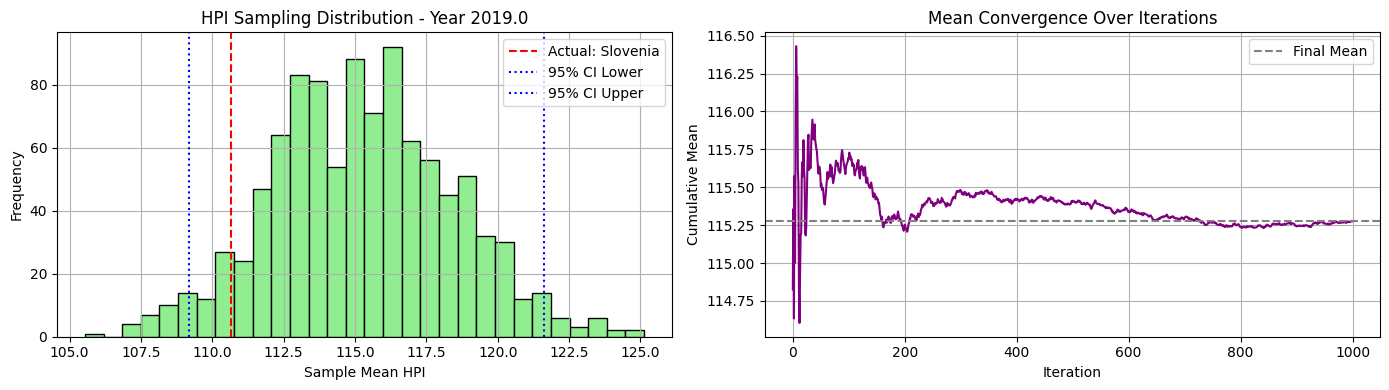

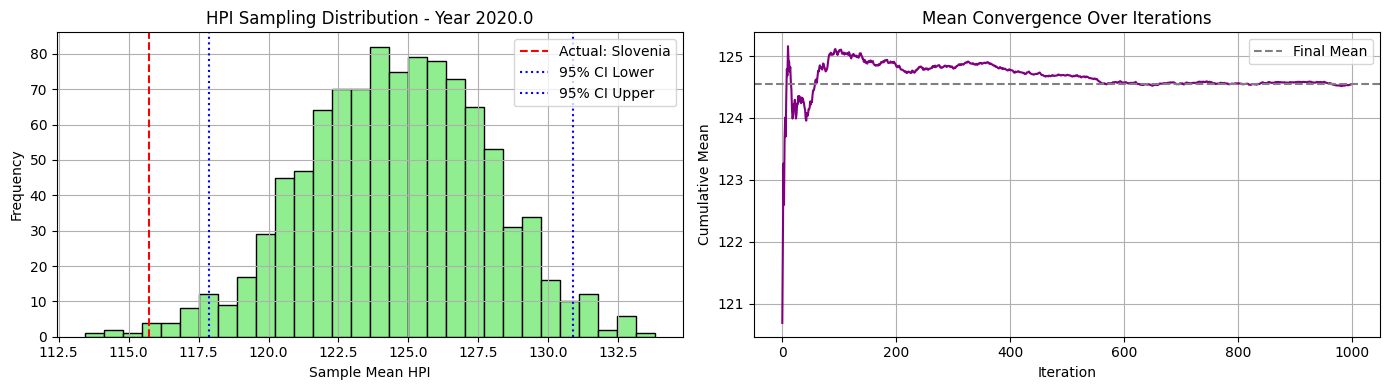

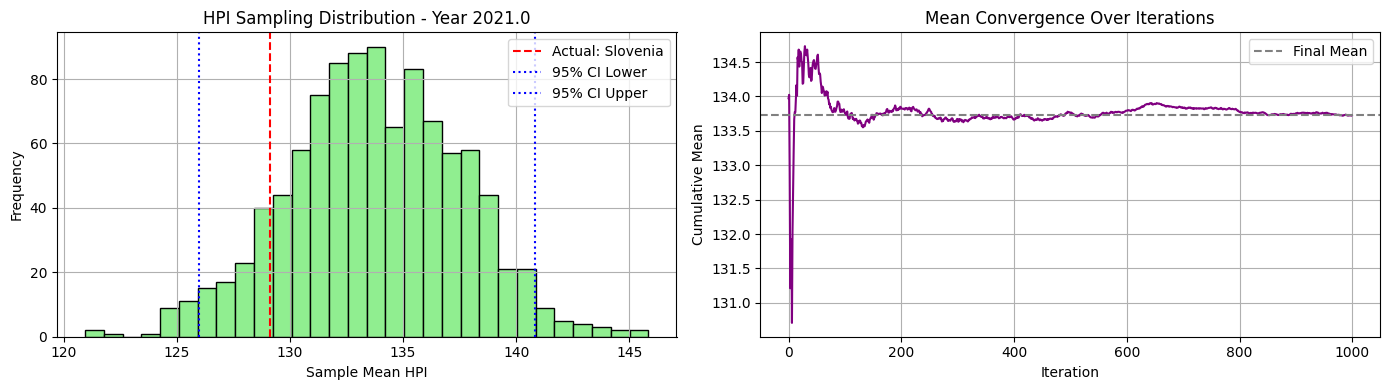

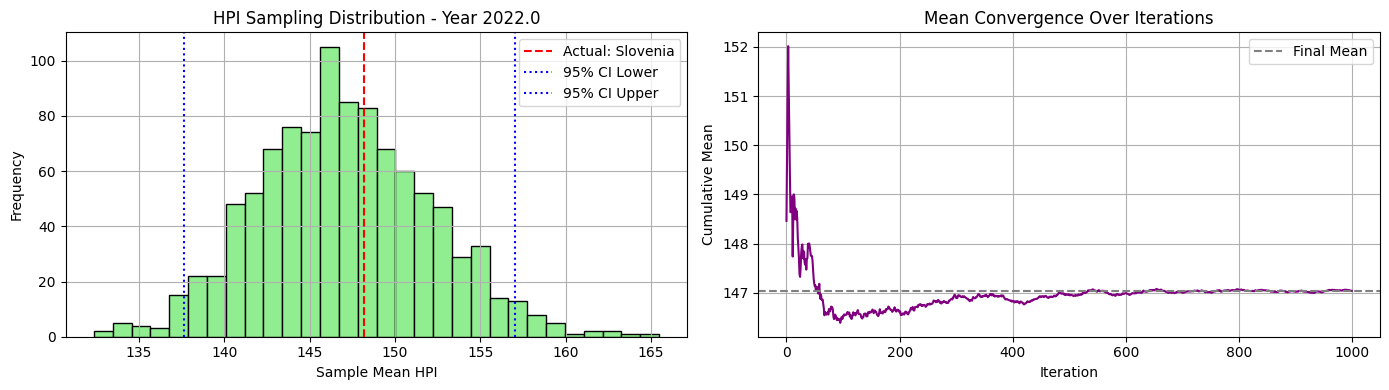

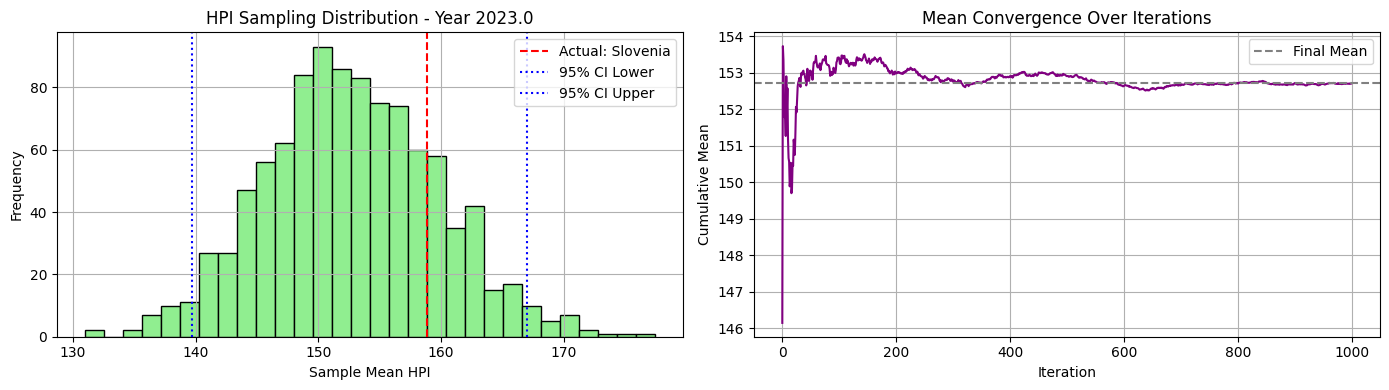

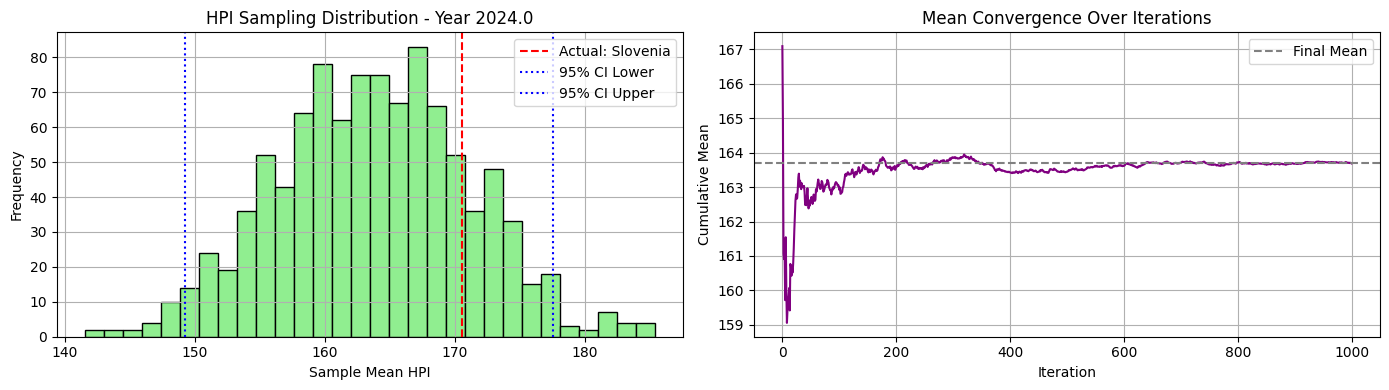

In [45]:
avg_mse_05, avg_mae_05, best_country_05, yearly_bootstrap_means_05, yearly_mean_05 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="Southern Europe", cluster_column="UNregion", start_year=2016)

In [40]:
df_continet[df_continet["UNregion"]=="Northern Europe"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
11,0.831886,4.815845,1,Denmark,DNK,Europe,Northern Europe
12,-12.509577,-0.623108,0,Estonia,EST,Europe,Northern Europe
13,-10.444790,1.013120,0,Finland,FIN,Europe,Northern Europe
18,5.939521,4.952702,1,Iceland,ISL,Europe,Northern Europe
19,-9.084436,-1.973917,0,Ireland,IRL,Europe,Northern Europe
23,-12.524267,-1.347875,0,Latvia,LVA,Europe,Northern Europe
24,-12.360475,-1.801832,0,Lithuania,LTU,Europe,Northern Europe
31,5.964392,4.513662,1,Norway,NOR,Europe,Northern Europe
46,7.288906,4.521602,1,Sweden,SWE,Europe,Northern Europe
49,1.955995,2.908009,1,United Kingdom,GBR,Europe,Northern Europe


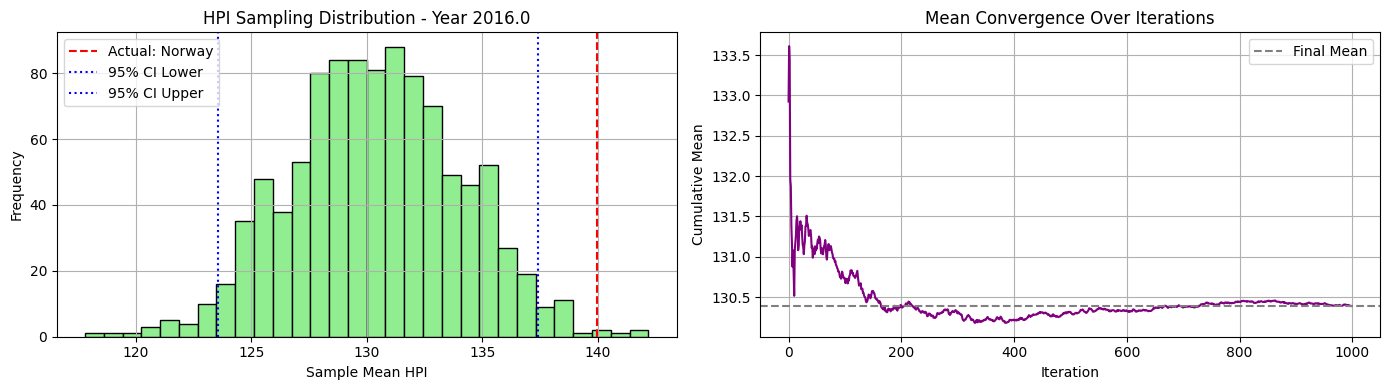

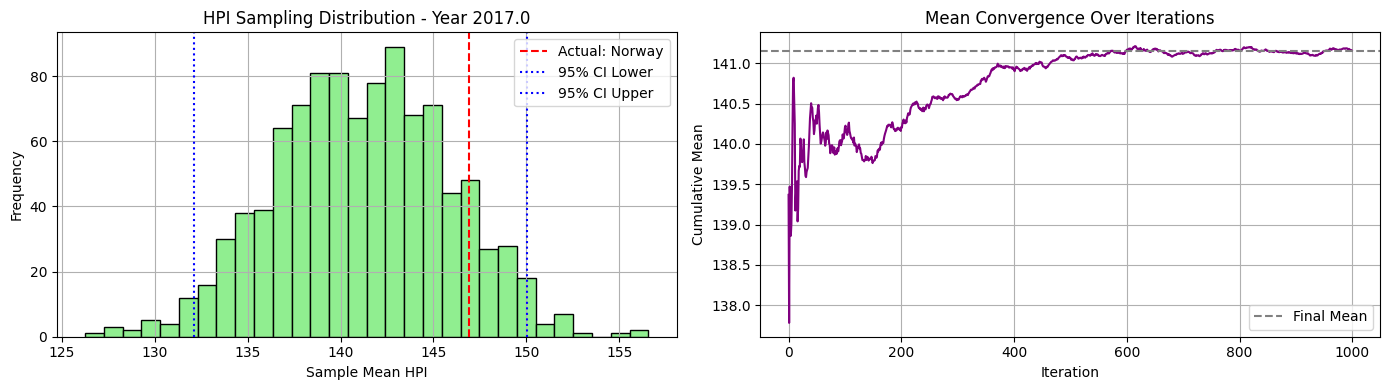

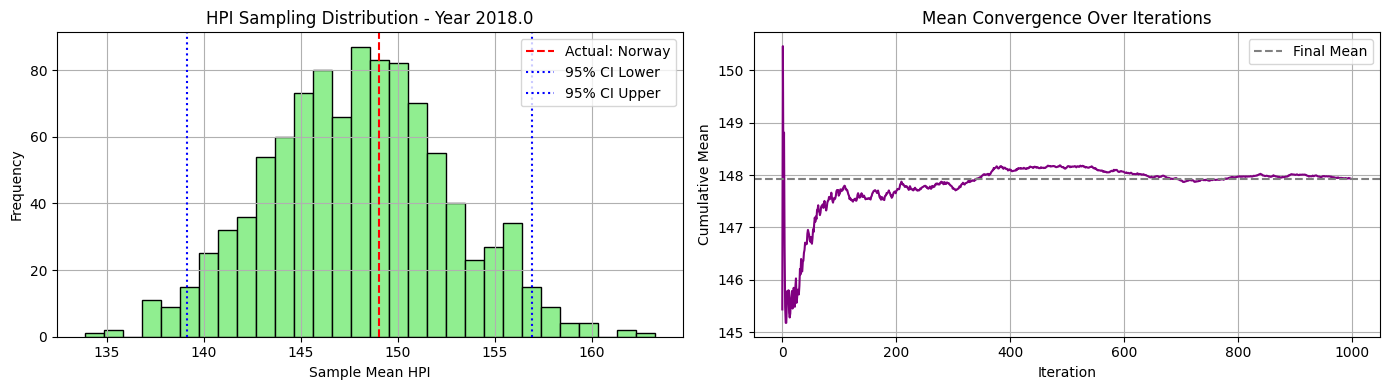

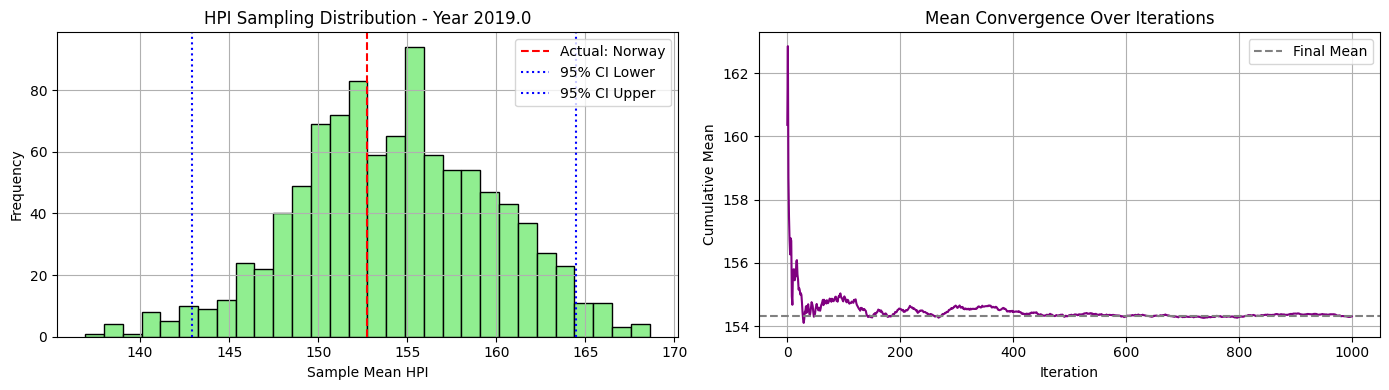

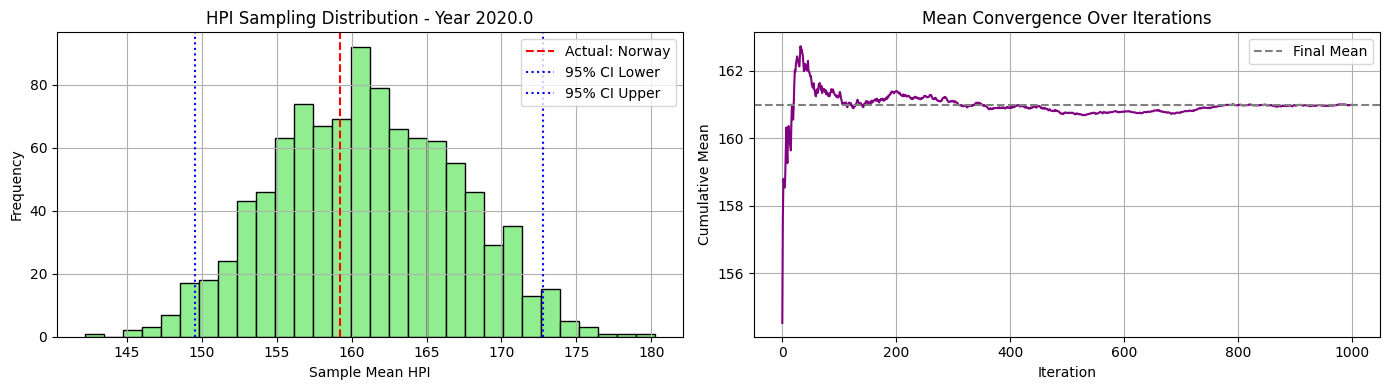

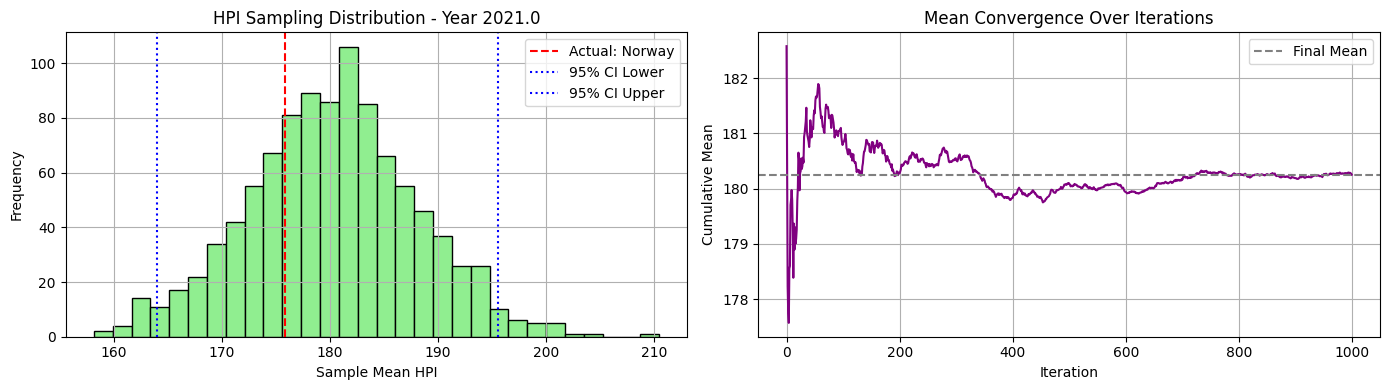

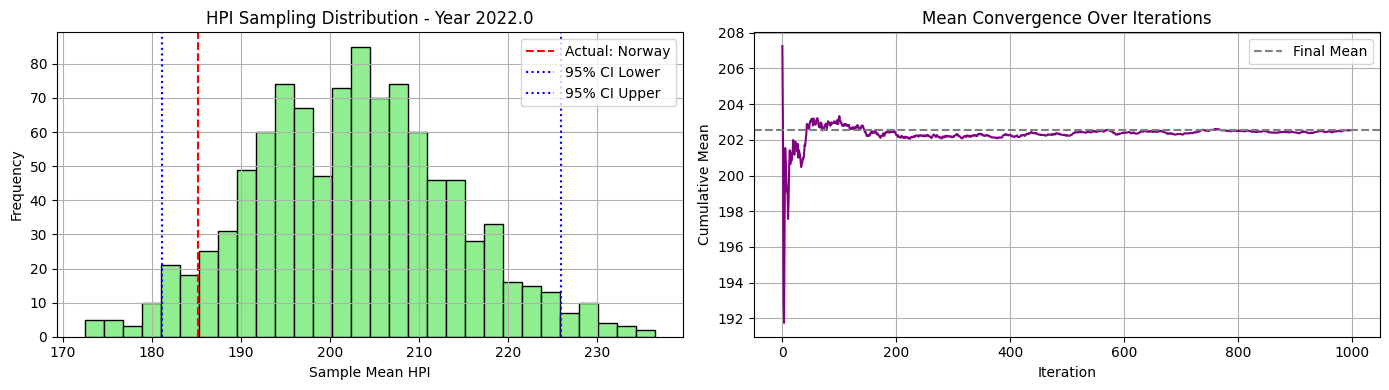

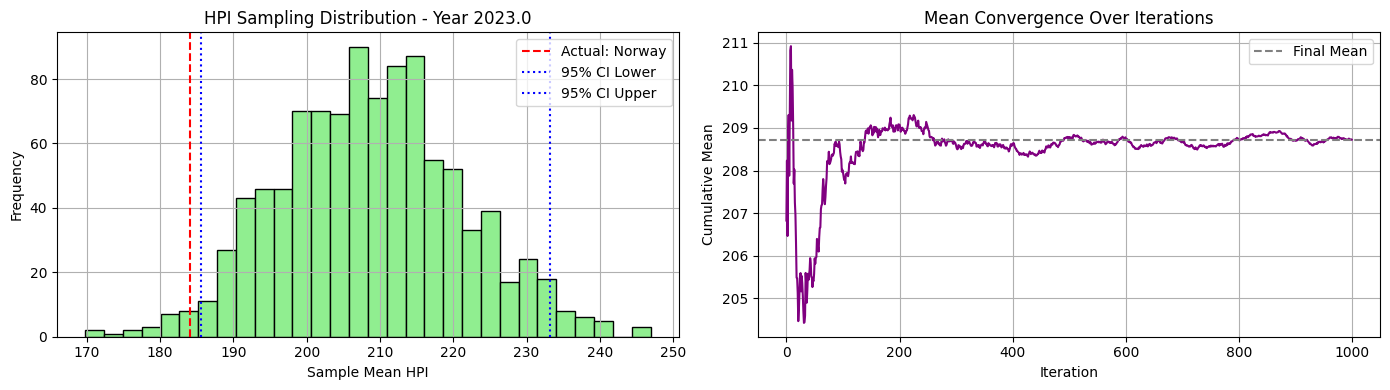

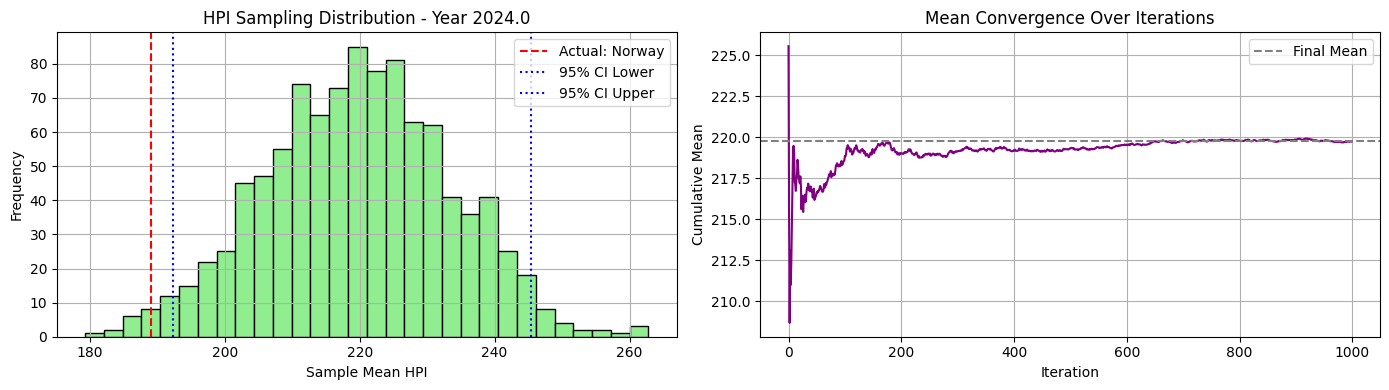

In [46]:
avg_mse_06, avg_mae_06, best_country_06, yearly_bootstrap_means_06, yearly_mean_06 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="Northern Europe", cluster_column="UNregion", start_year=2016)

In [39]:
df_continet[df_continet["UNregion"]=="Western Asia"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
9,-12.524878,-1.895969,0,Cyprus,CYP,Asia,Western Asia
20,0.112871,2.014085,1,Israel,ISR,Asia,Western Asia


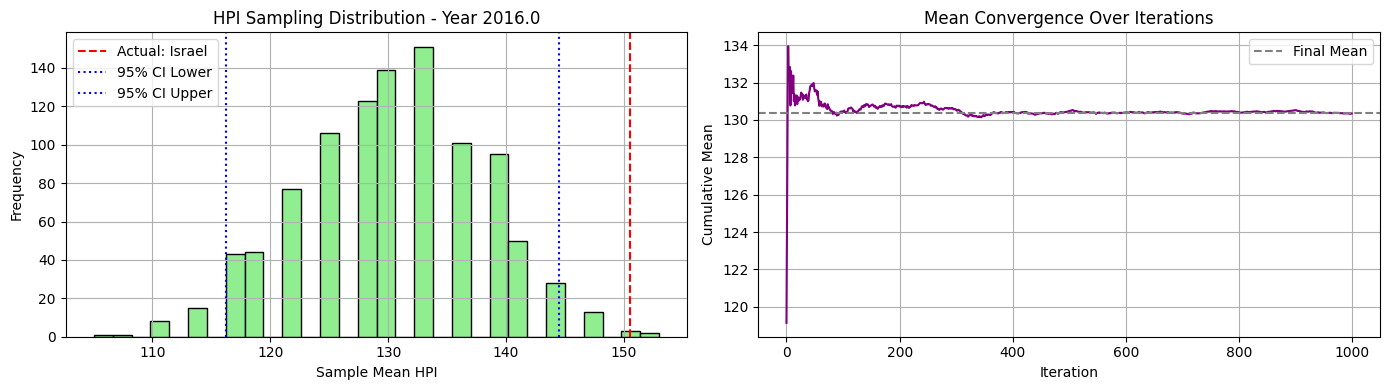

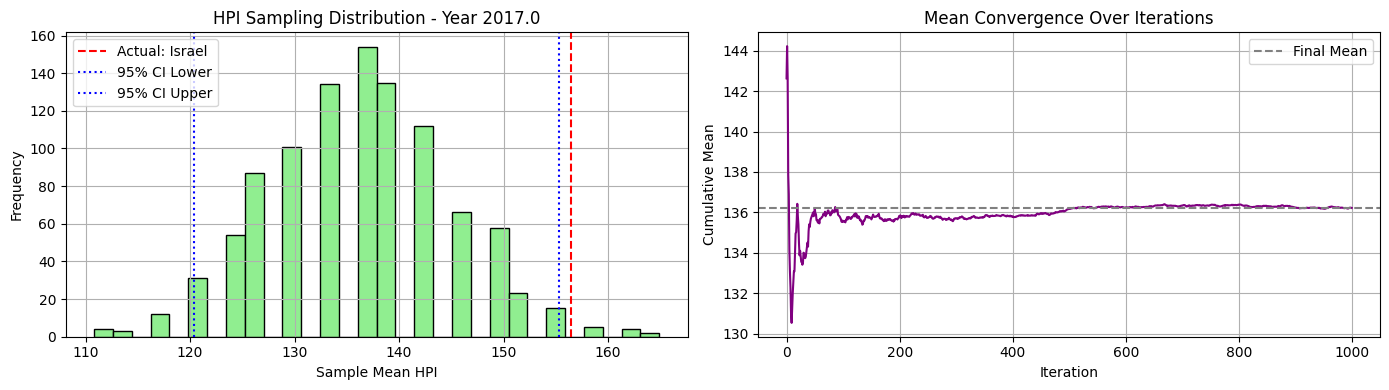

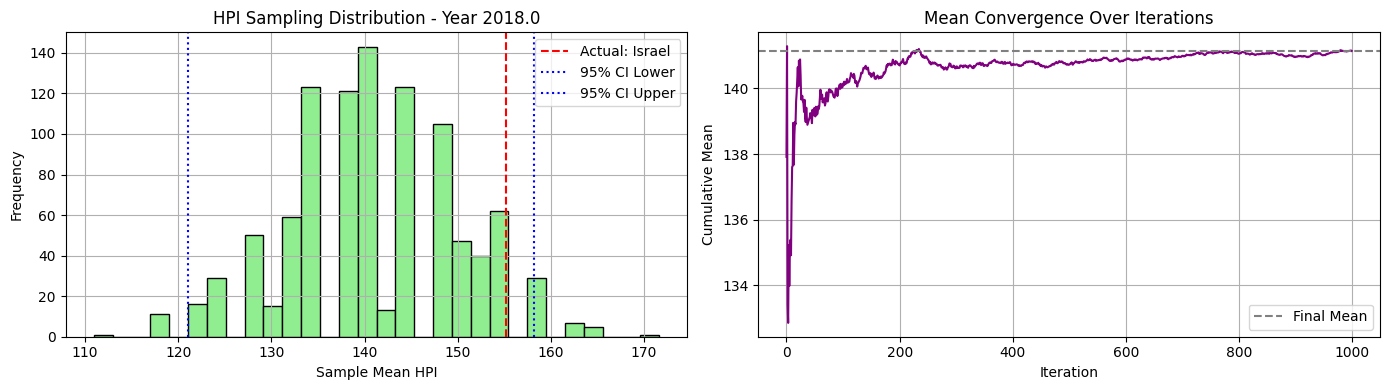

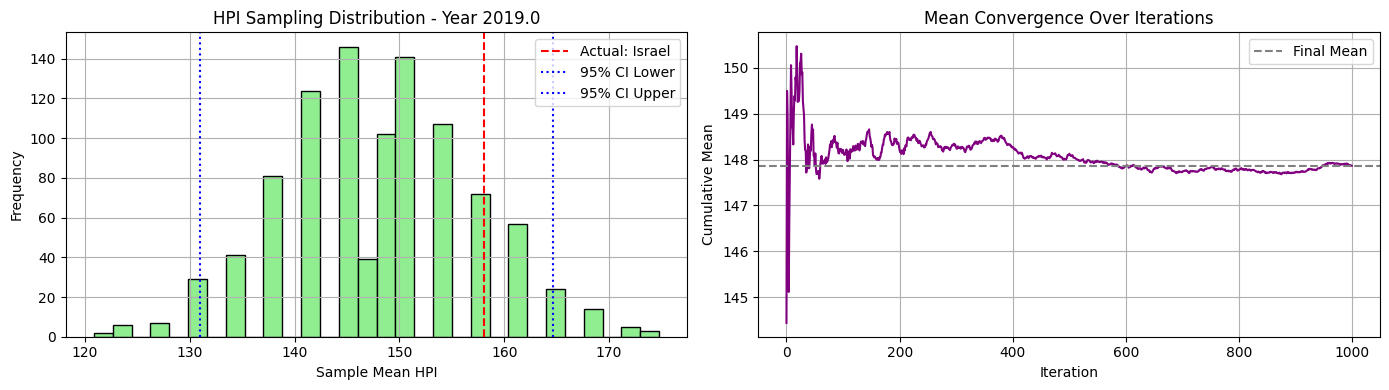

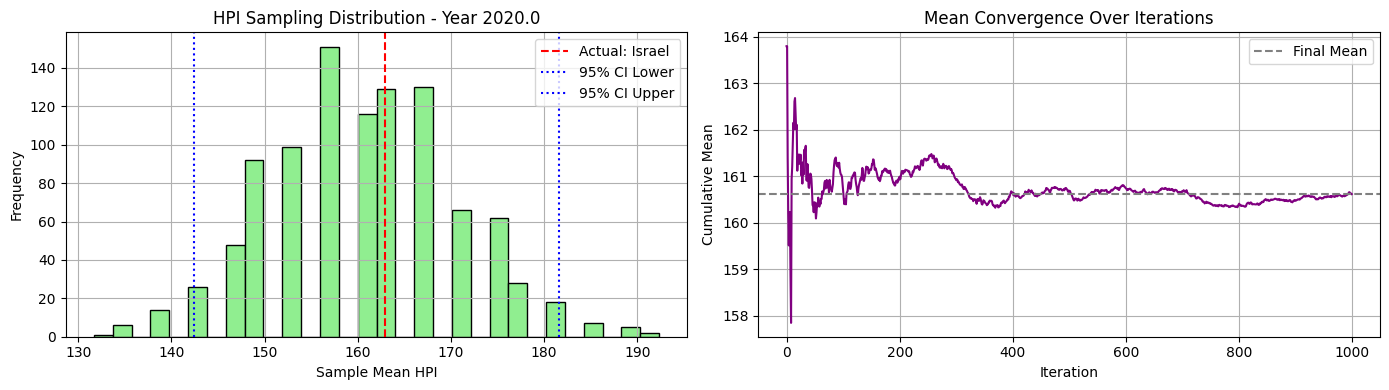

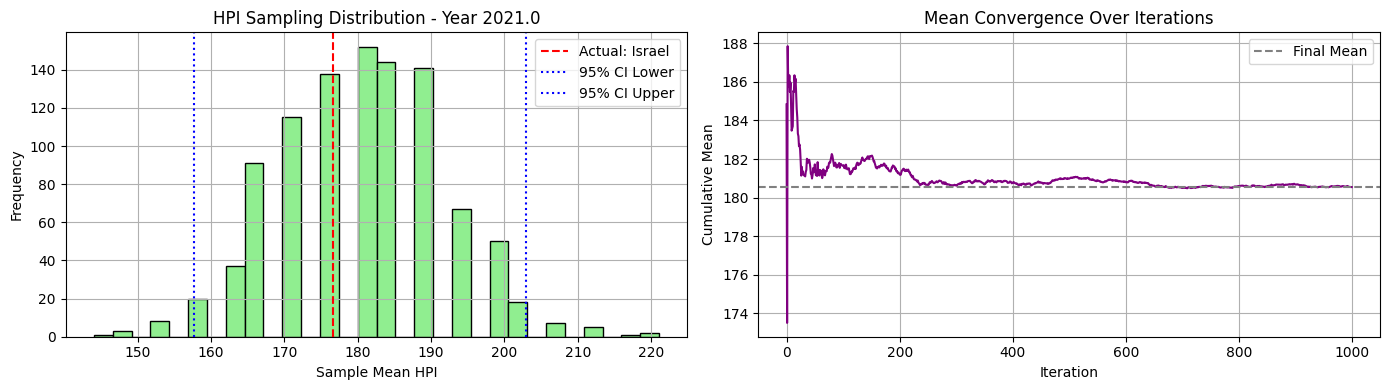

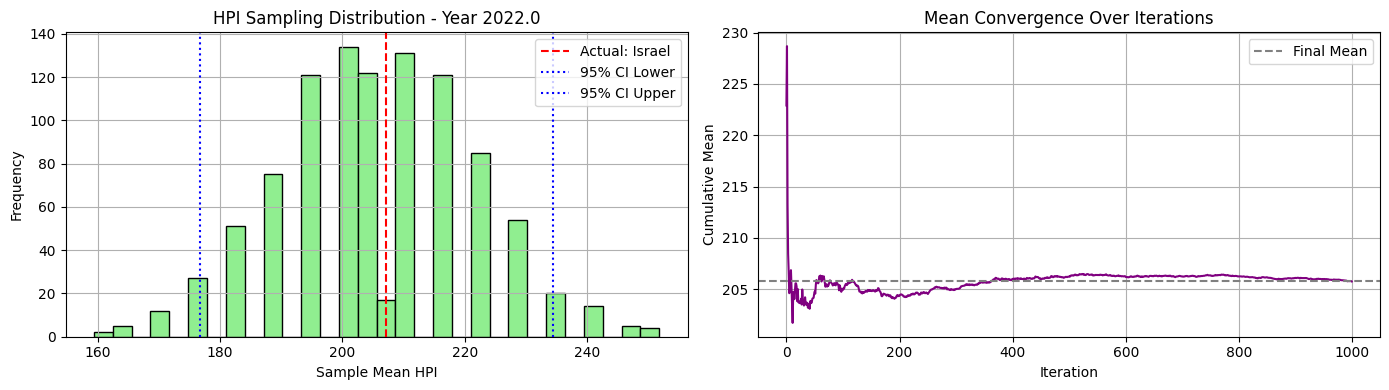

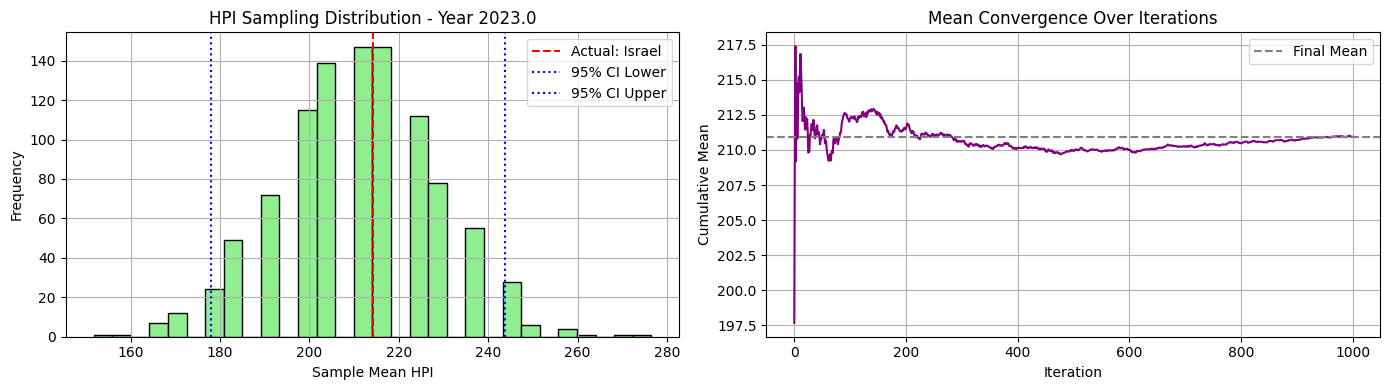

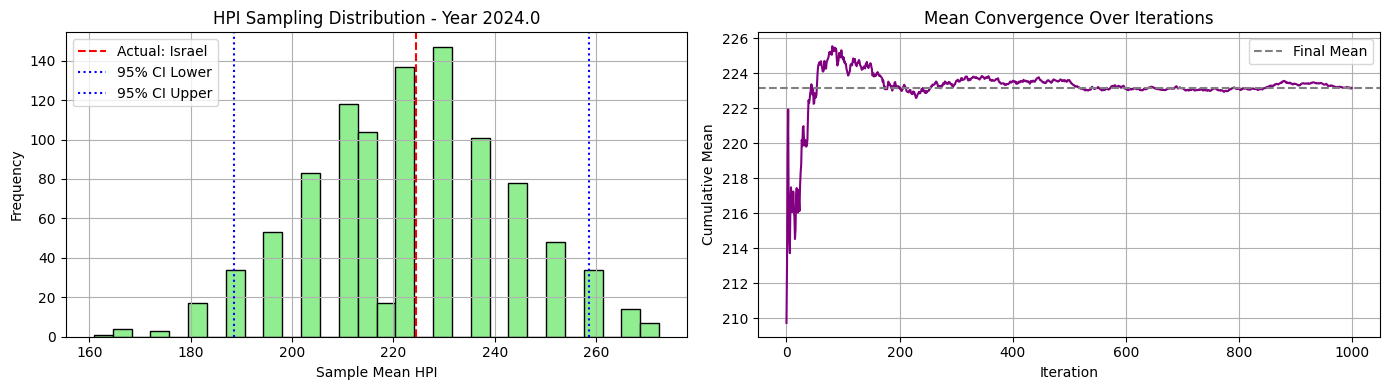

In [47]:
avg_mse_07, avg_mae_07, best_country_07, yearly_bootstrap_means_07, yearly_mean_07 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="Western Asia", cluster_column="UNregion", start_year=2016)

In [41]:
df_continet[df_continet["UNregion"]=="Eastern Asia"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
22,13.302636,3.387087,1,Japan,JPN,Asia,Eastern Asia
44,13.066557,1.732150,1,South Korea,KOR,Asia,Eastern Asia


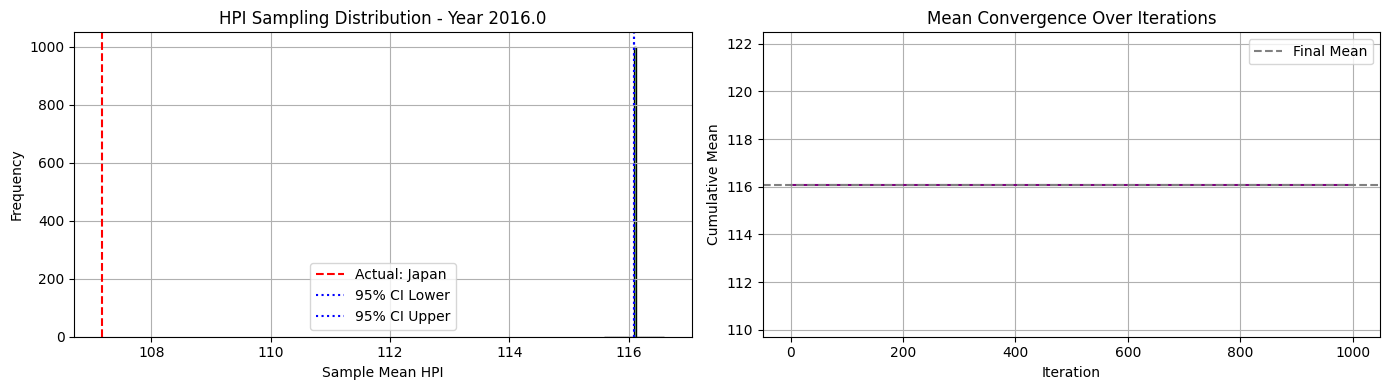

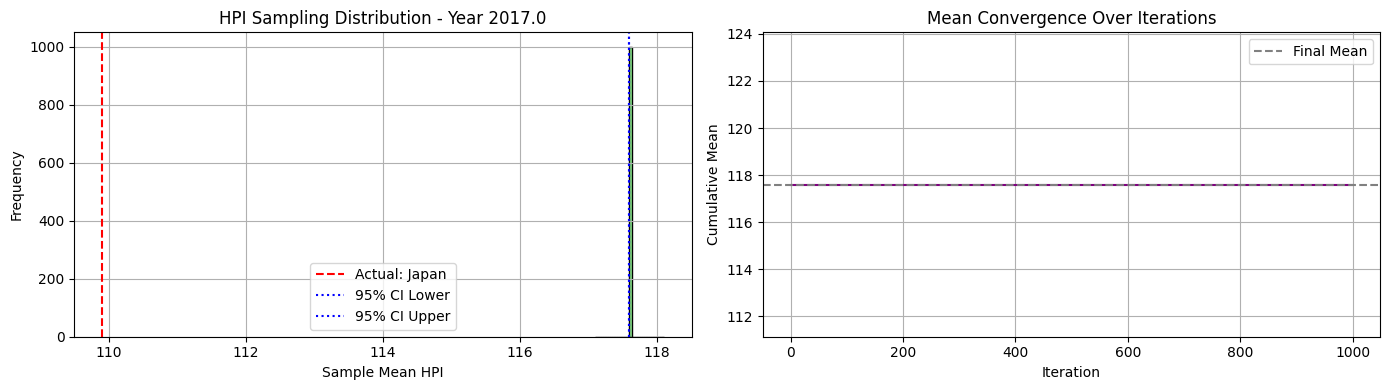

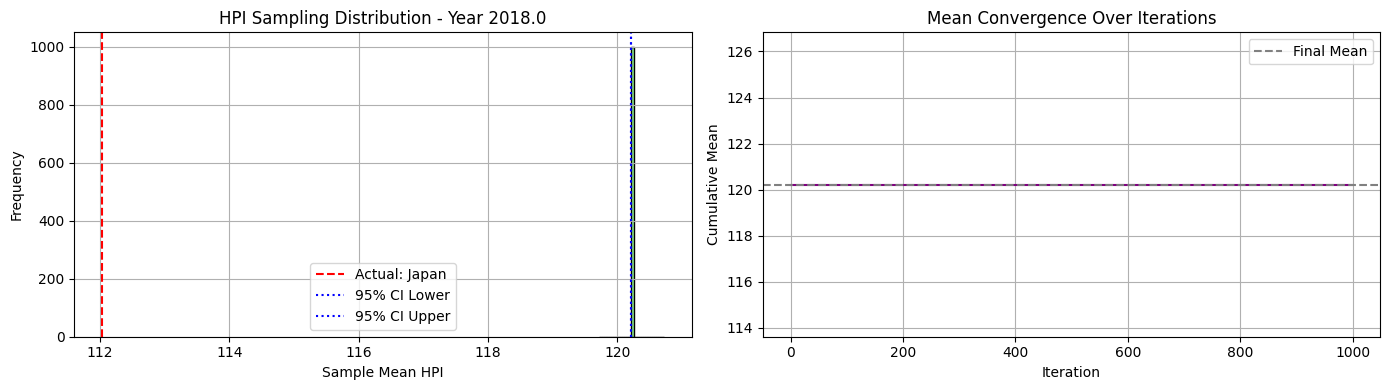

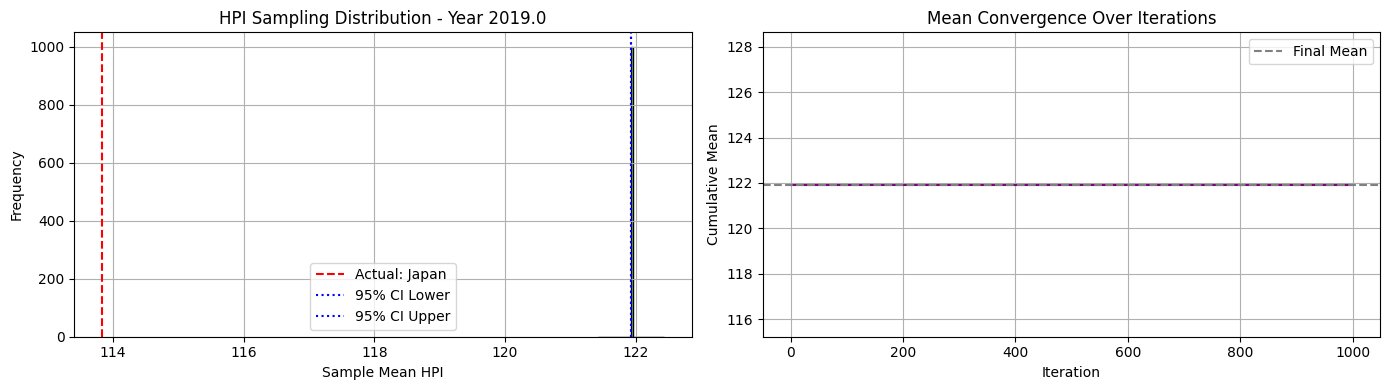

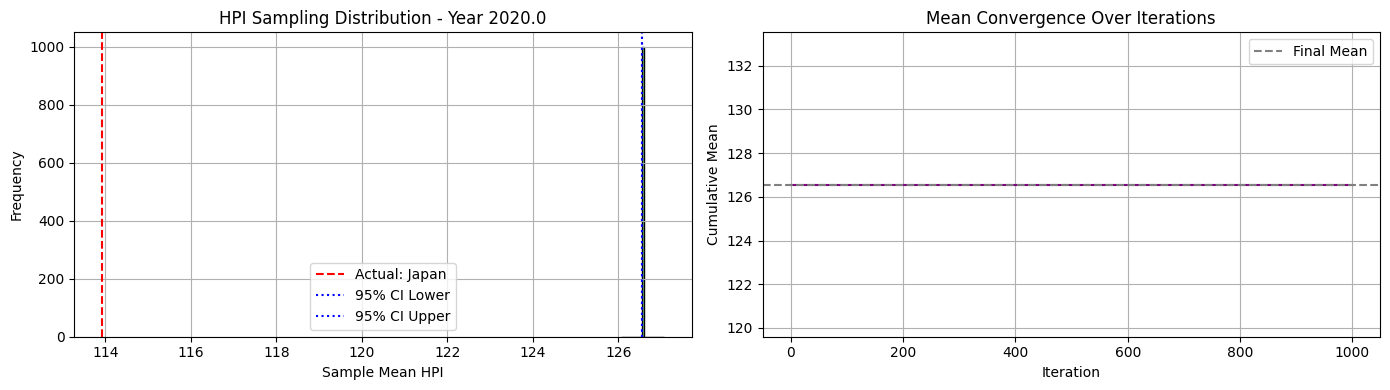

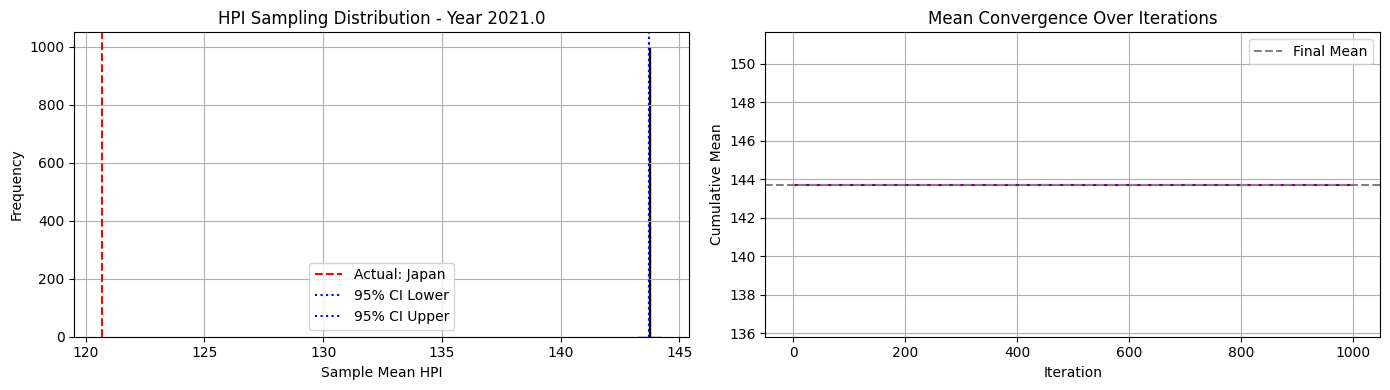

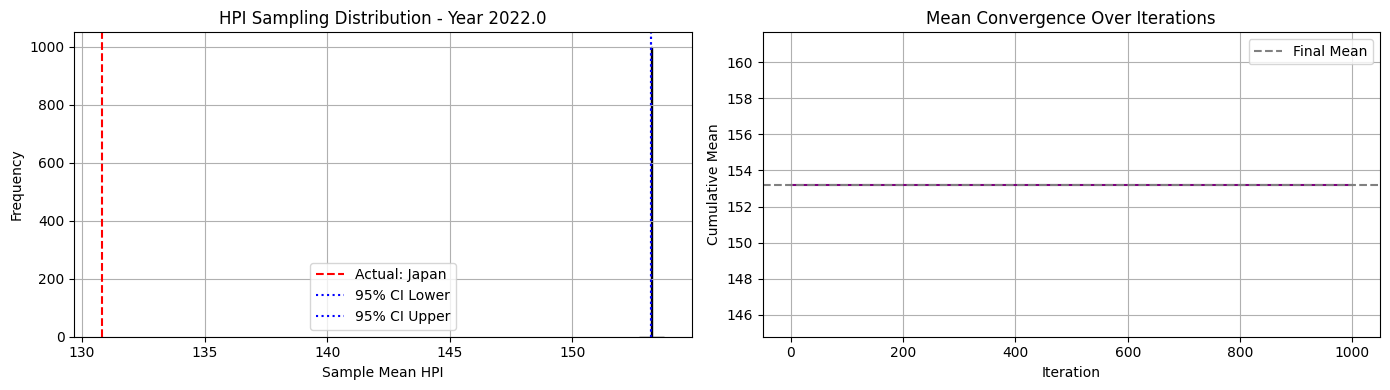

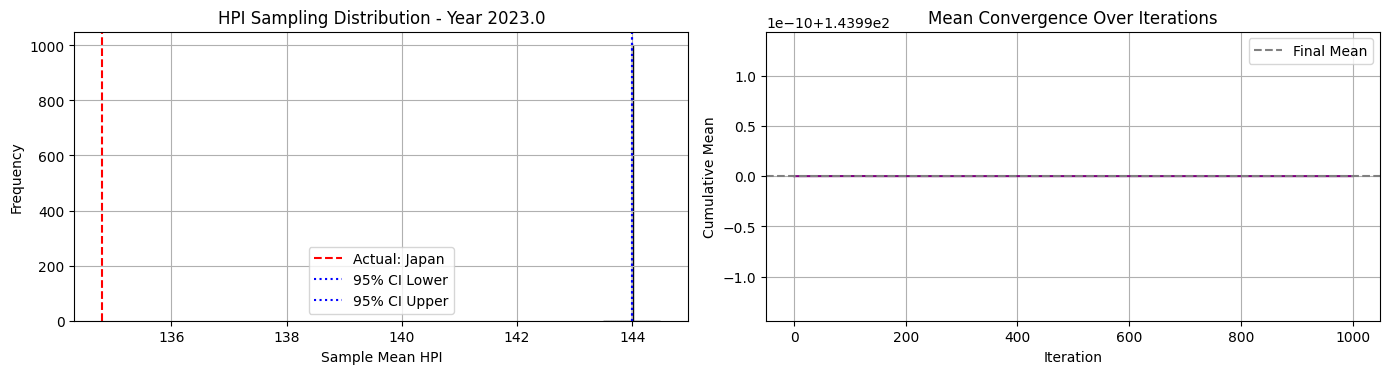

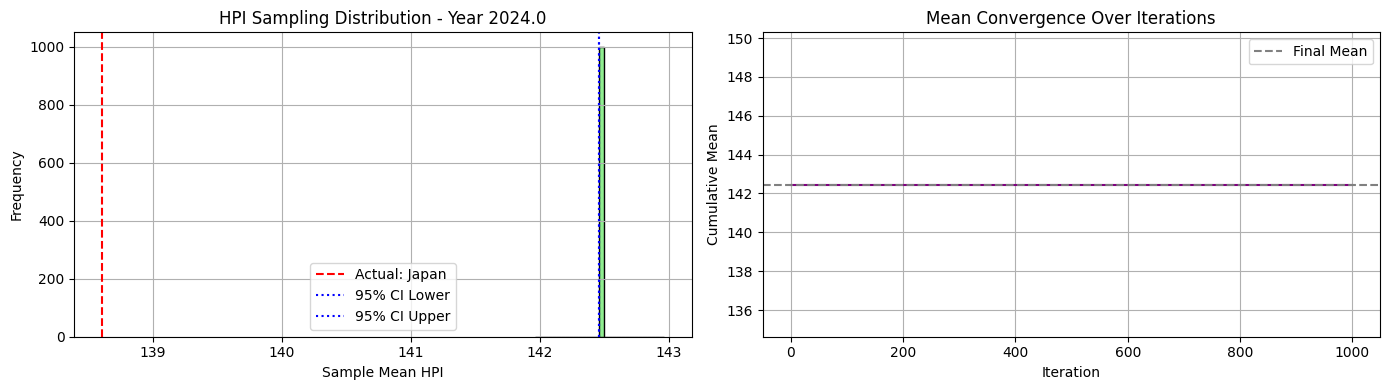

In [48]:
avg_mse_08, avg_mae_08, best_country_08, yearly_bootstrap_means_08, yearly_mean_08 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="Eastern Asia", cluster_column="UNregion", start_year=2016)

In [42]:
df_continet[df_continet["UNregion"]=="South-eastern Asia"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
26,0.080285,0.776505,1,Malaysia,MYS,Asia,South-eastern Asia
34,12.456768,-4.271766,1,Philippines,PHL,Asia,South-eastern Asia
40,-4.441037,6.265166,0,Singapore,SGP,Asia,South-eastern Asia
48,12.002916,-0.255752,1,Thailand,THA,Asia,South-eastern Asia


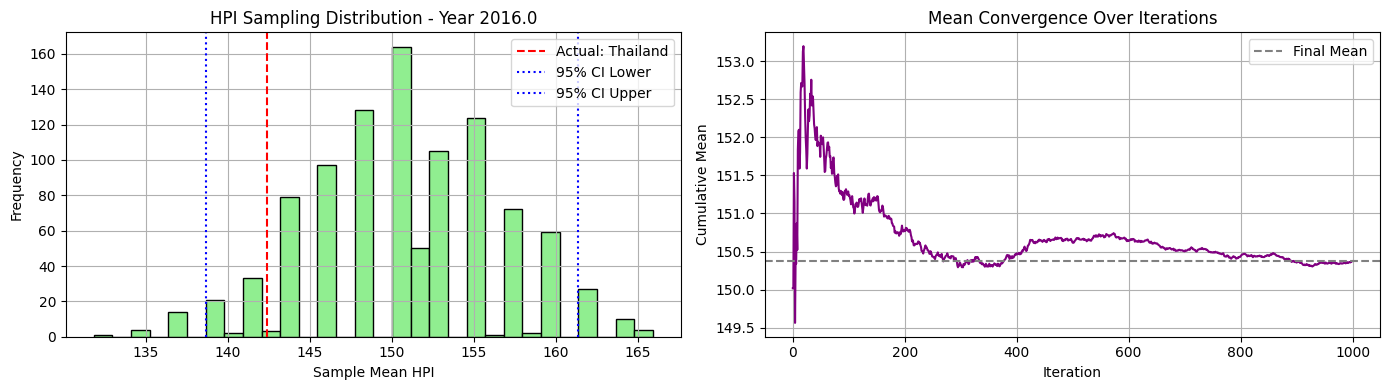

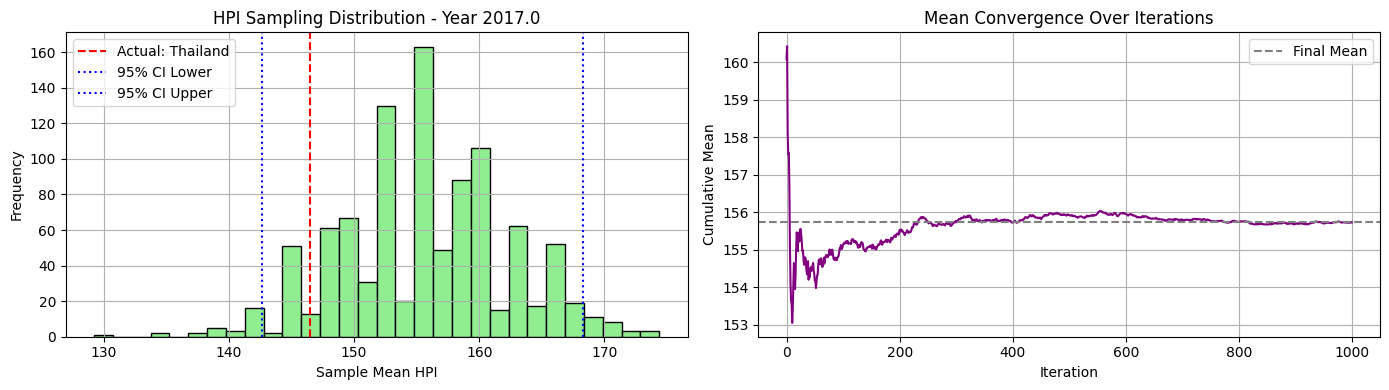

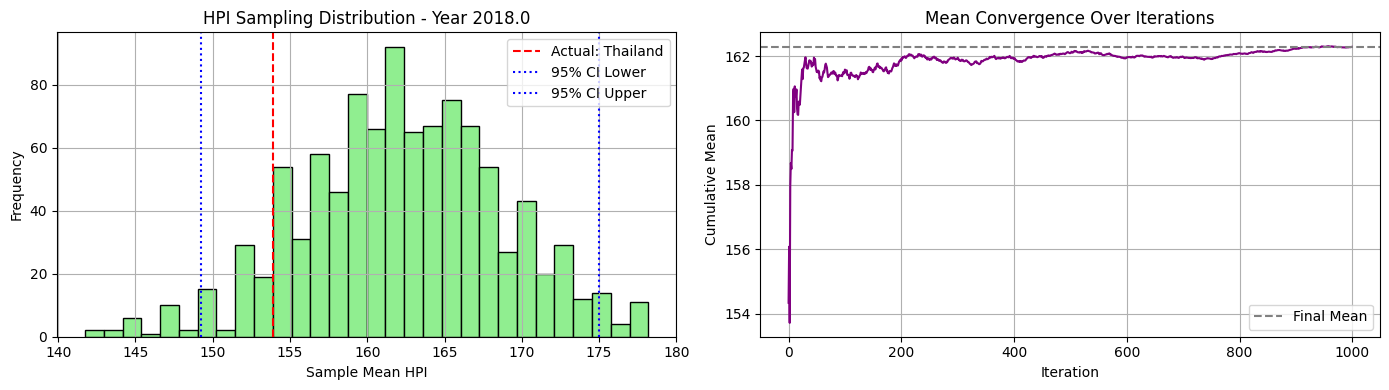

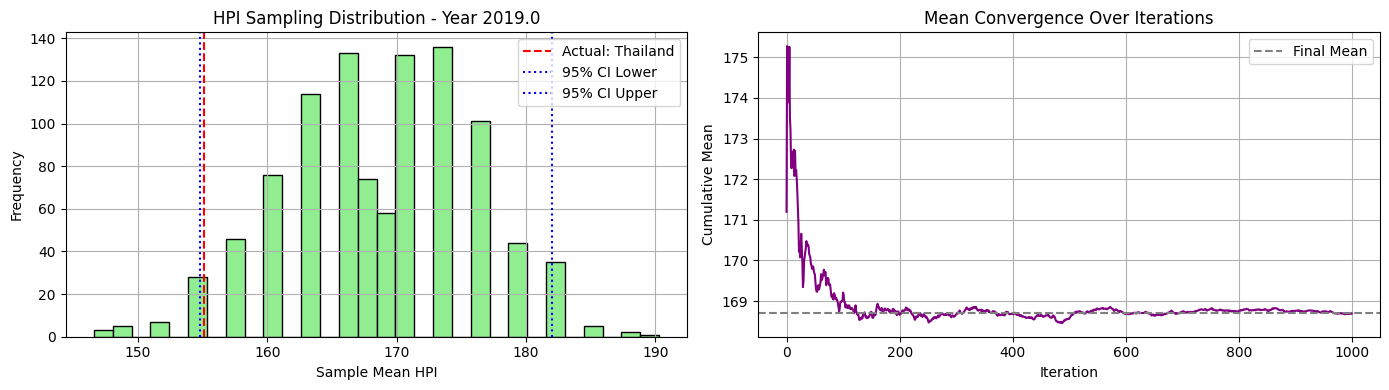

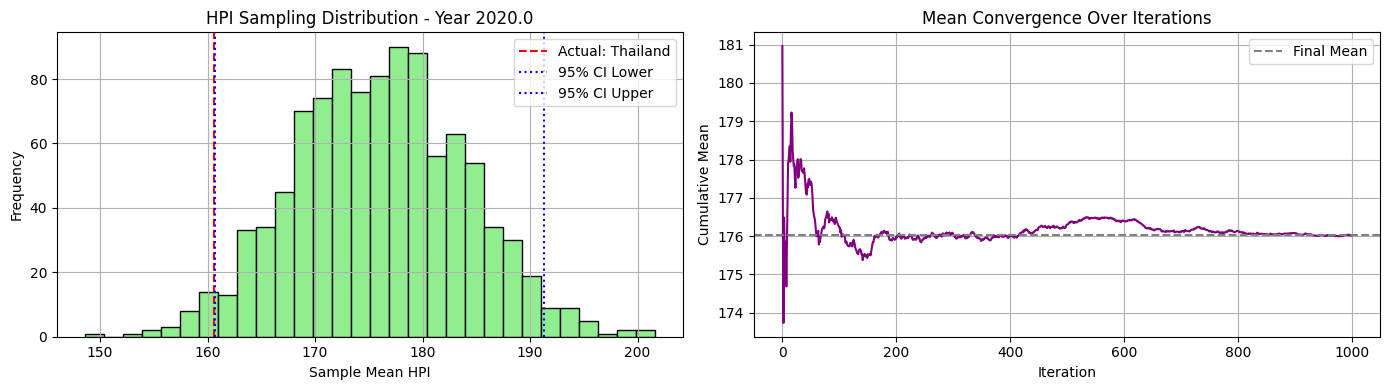

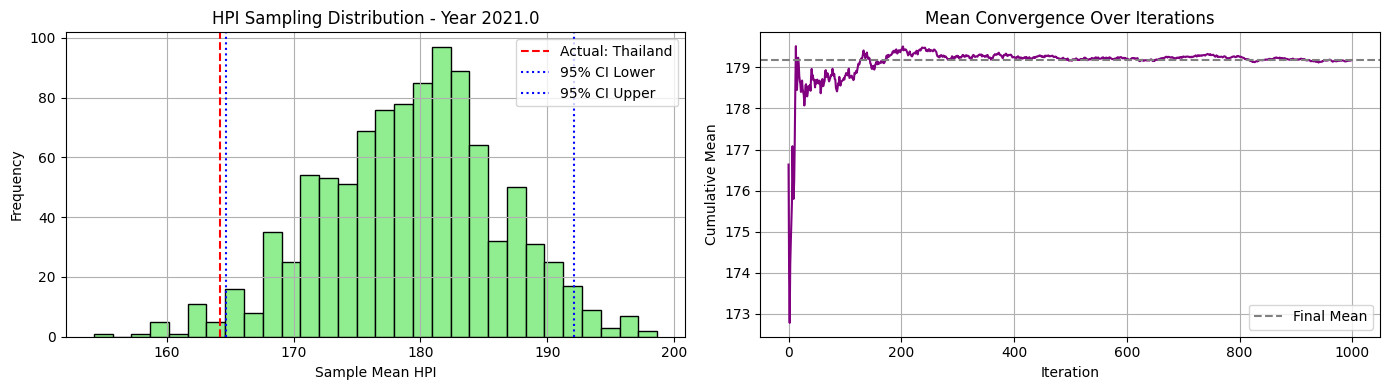

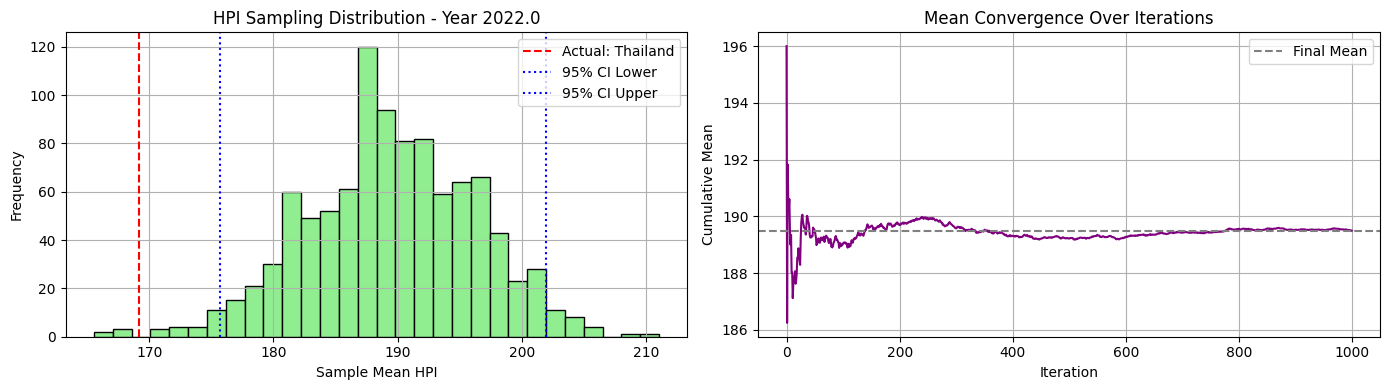

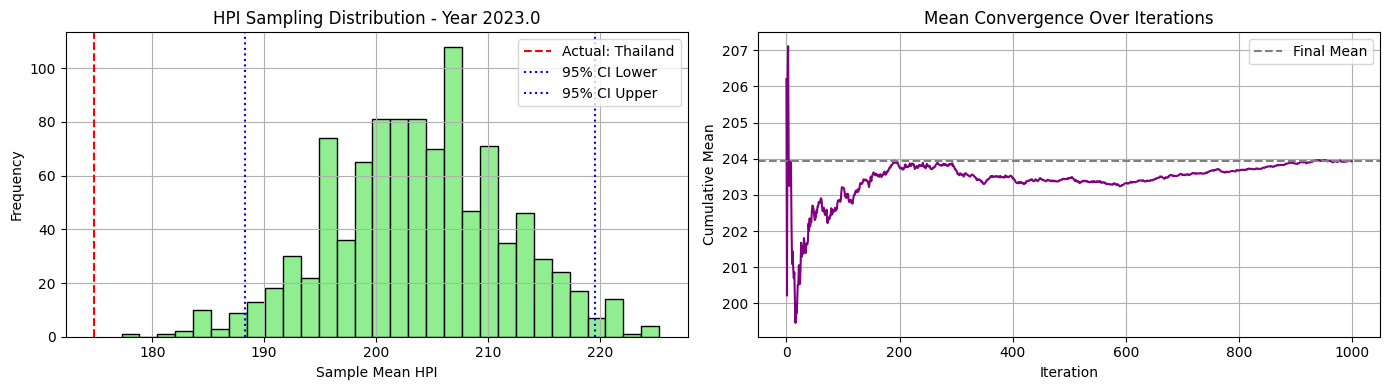

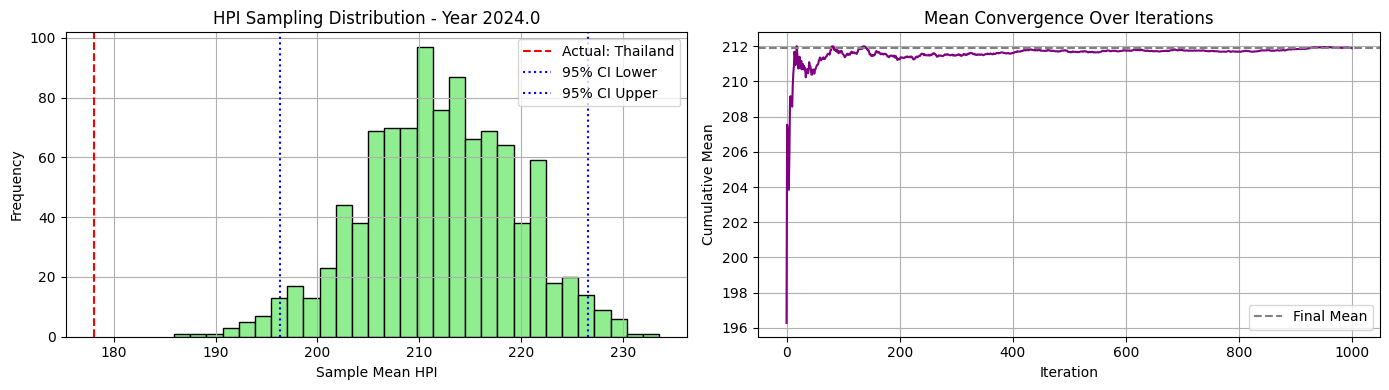

In [49]:
avg_mse_09, avg_mae_09, best_country_09, yearly_bootstrap_means_09, yearly_mean_09 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=one_point_countries_win6, cluster_id="South-eastern Asia", cluster_column="UNregion", start_year=2016)

In [45]:
df_continet[df_continet["UNregion"]=="Southern Africa"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
43,6.988732,0.04535,1,South Africa,ZAF,Africa,Southern Africa


### See errors

In [51]:
one_point_countries_win6.UNregion.unique()

array(['Australia and New Zealand', 'Western Europe', 'South America',
       'Eastern Europe', 'Northern America', 'Southern Europe',
       'Western Asia', 'Northern Europe', 'Southern Asia', 'Eastern Asia',
       'South-eastern Asia', 'Southern Africa'], dtype=object)

In [52]:
errors_continent = {
    'Australia and New Zealand': [avg_mse_00, avg_mae_00],
    'Western Europe': [avg_mse_01, avg_mae_01],
    'South America': [avg_mse_02, avg_mae_02],
    'Eastern Europe': [avg_mse_03, avg_mae_03],
    'Northern America': [avg_mse_04, avg_mae_04],
    'Southern Europe': [avg_mse_05, avg_mae_05],
    'Northern Europe': [avg_mse_06, avg_mae_06],
    'Western Asia': [avg_mse_07, avg_mae_07],
    'Eastern Asia': [avg_mse_08, avg_mae_08],
    'South-eastern Asia': [avg_mse_09, avg_mae_09]
    
}

# Convertir a DataFrame
df_errors_continent = pd.DataFrame.from_dict(errors_continent, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors_continent = df_errors_continent.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors_continent)


📊 Cluster Sampling Error Summary:
                           Average MSE  Average MAE
Australia and New Zealand    2676.0321      48.3033
Western Europe                845.2510      24.8099
South America                2092.8748      35.4718
Eastern Europe               1745.2660      30.5767
Northern America              355.1260      16.1652
Southern Europe               706.3404      21.6423
Northern Europe              2355.3733      37.9246
Western Asia                 7534.1768      69.7650
Eastern Asia                  173.4362      11.5500
South-eastern Asia           2108.2079      41.3232


In [53]:
df_errors_continent['Average MSE'].mean()

np.float64(2059.20845)

In [54]:
df_errors_continent['Average MAE'].mean()

np.float64(33.7532)

In [70]:
one_point_countries_win6['PC1'] = pca_df['PC1']

In [71]:
one_point_countries_win6['PC2'] = pca_df['PC2']

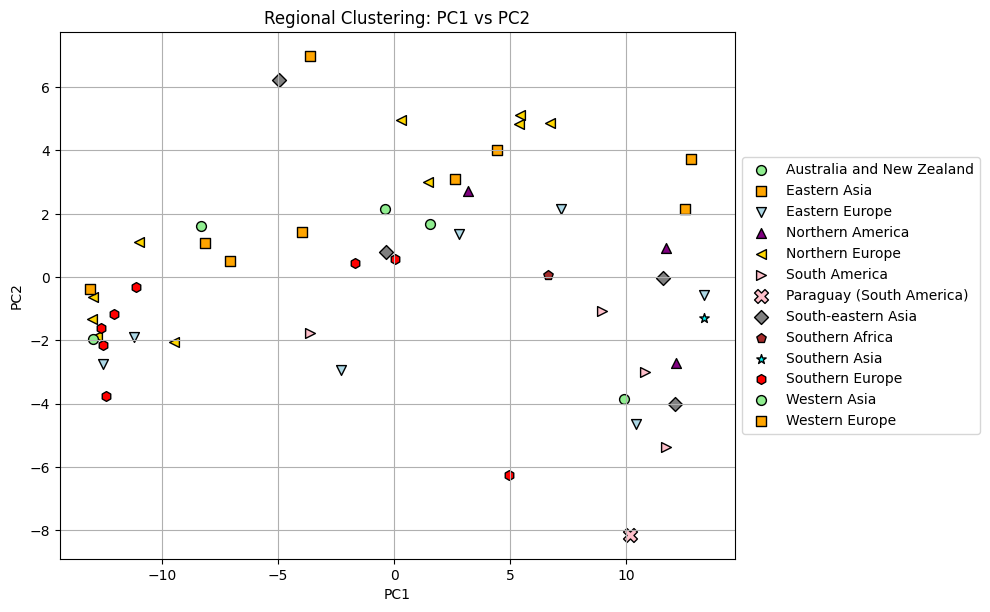

In [80]:
plot_region_clusters(one_point_countries_win6, 'PC1', 'PC2')

In [73]:
from sklearn.metrics import silhouette_samples
from matplotlib import cm

In [76]:
def plot_silhouette_from_labels(df, x_col, y_col, label_col='UNregion'):
    """
    Generates a silhouette plot using predefined cluster labels (e.g., UNregion).

    Parameters:
    - df: DataFrame containing the data
    - x_col, y_col: columns for the feature space
    - label_col: column with cluster labels (e.g., UNregion)

    Returns:
    - silhouette_avg: average silhouette coefficient
    """
    X = df[[x_col, y_col]].values
    labels_raw = df[label_col].values
    unique_labels = np.unique(labels_raw)

    # Map string labels to integers
    label_map = {label: idx for idx, label in enumerate(unique_labels)}
    labels = np.array([label_map[label] for label in labels_raw])

    n_clusters = len(unique_labels)
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    # 🔍 Aumentar tamaño de figura para evitar encimamiento
    plt.figure(figsize=(10, max(6, n_clusters * 0.6)))  # Ajusta alto dinámicamente

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'{label}' for label in unique_labels])
    plt.ylabel('Cluster (Region)')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by region')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg


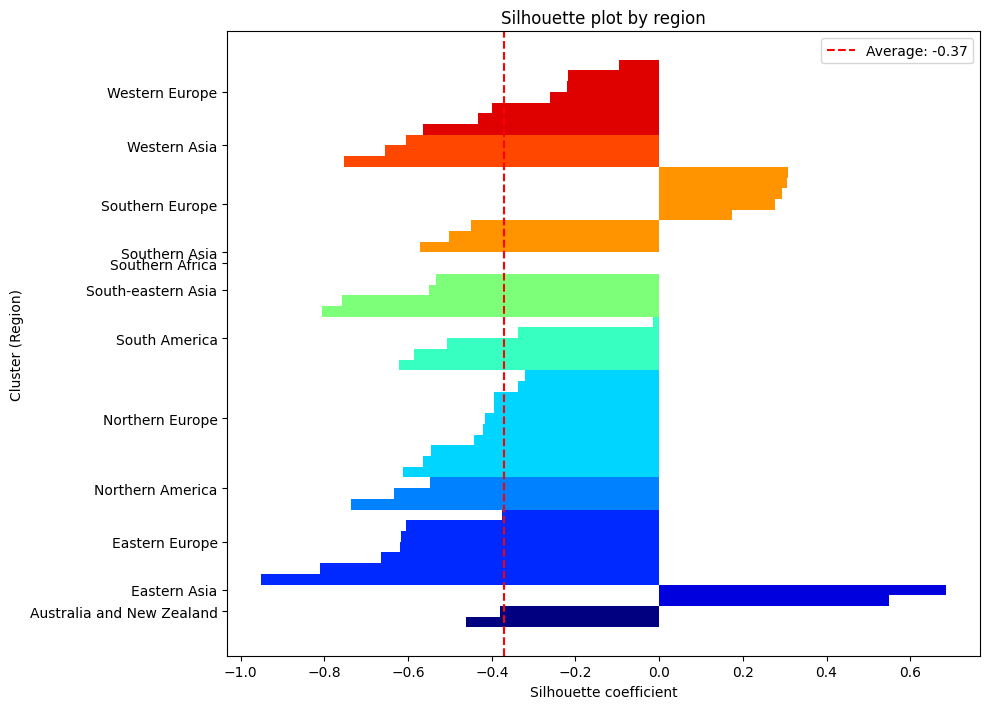

In [78]:
silhouette_regions = plot_silhouette_from_labels(one_point_countries_win6, 'PC1', 'PC2', label_col='UNregion')

### Log Performance

In [81]:
log_df = pd.read_parquet('../data/log_performance/new_log_performance.parquet')

In [83]:
pd.set_option('display.max_columns', None)

In [85]:
new_entry2 = {
    'experiment_name': 'region_baseline_cluster',
    'experiment_date': '2025-09-26 18:16',
    'premacroecon_conversion_transform': None,
    'countries_used_for_clustering': 53,
    'clustering_model': 'KMeans',
    'n_clusters': 12,
    'init_method': None,
    'n_init': None,
    'max_iter': None,
    'random_state': None,
    'used_elbow_method': None,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhouette_regions,
    'transformations_clustering': 'StandardScaler, log transformation',
    'outliers_handling_clustering': 'Winsorization x6',
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': False,
    'transformations_sampling': 'Winsorization x2, rounding',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'sampling_seed': None,
    'excluded_countries_count': 53,
    'mse_score': df_errors_continent['Average MSE'].mean(),
    'mae_score': df_errors_continent['Average MAE'].mean(),
    'source_notebook': 'hypothesis_test_30',
    'pca_ratio_sum': None,
    'pca_ratio_values': None,
    'Variance_Cluster_0': None,
    'Variance_Cluster_1': None,
    'Variance_Cluster_2': None,
    'Variance_Cluster_3': None,
    'IQR_Count_Cluster_0':None,
    'IQR_Count_Cluster_1':None,
    'IQR_Count_Cluster_2': None,
    'IQR_Count_Cluster_3': None   
}

In [86]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry2])], ignore_index=True)

C:\Users\lucas\AppData\Local\Temp\ipykernel_20104\3551463810.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log_df = pd.concat([log_df, pd.DataFrame([new_entry2])], ignore_index=True)


In [88]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [89]:
log_df.to_parquet('../data/log_performance/new_log_performance.parquet')

In [90]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,NaN,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,687.795150,20.008850,hypothesis_test_017,NaN,None,553.92,705.83,NaN,NaN,49.0,56.0,NaN,NaN
2,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1090.584800,23.302850,hypothesis_test_015,NaN,None,956.43,1130.45,NaN,NaN,53.0,50.0,NaN,NaN
3,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1814.085733,29.407333,hypothesis_test_015,NaN,None,1228.13,1590.76,3058.83,871.95,46.0,76.0,37.0,48.0
4,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1118.876100,23.644450,hypothesis_test_013,NaN,None,1177.08,975.18,NaN,NaN,54.0,51.0,NaN,NaN
5,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1145.655433,24.226533,hypothesis_test_013,NaN,None,1257.22,1050.94,927.59,NaN,53.0,56.0,50.0,NaN
6,kmeans_++_2c_h2_countries_exclude,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.428486,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1131.624450,24.274950,hypothesis_test_018,NaN,None,1024.42,1152.36,NaN,NaN,49.0,49.0,NaN,NaN
7,kmeans_++_2c_h2_4delete_countries_exclude,2025-09-17 15:31,None,49,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420890,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,49.0,860.984600,21.624550,hypothesis_test_024,NaN,None,988.52,661.65,NaN,NaN,49.0,49.0,NaN,NaN
8,kmeans_++_2c_h2_2delete_countries_exclude,2025-09-18 17:00,None,51,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420313,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'live

In [91]:
one_point_countries_win6.to_parquet('../data/clusters/region_cluster.parquet')